# FIT5196 Assessment 2 - Dirty-Data Repair, Outlier Removal and Validation

**Group:** Group018  
**Stage:** Shared foundations, dirty-data repair (1.1), outlier removal (1.3) and concurrent Task 2 evidence

This notebook covers Task 1 (dirty repair 1.1, missing recovery 1.2, outlier removal 1.3),
Task 2 (audit log 2.1 and validation 2.2-2.5) and Task 3 (customer profiling).
Run all cells from the top; it recreates the three cleaned CSVs and `audit_log.csv`.

## 0. Configuration and environment

This section keeps identifiers, input and output paths, expected columns, tolerances and the random
seed in one place.

Expected layout: the extracted `Group018_A2` package contents (three input CSVs, `warehouses.csv`,
manifests, README and `resources/`) sit in `data/` beside this notebook. Inputs are only read
from `DATA_DIR`; the three cleaned CSVs and `audit_log.csv` are written to `OUTPUT_DIR`.

In [1]:
from pathlib import Path

GROUP_ID = "Group018"
DATA_DIR = Path("data")
RANDOM_SEED = 5196

OUTPUT_DIR = Path(".")
DIRTY_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_dirty_clean.csv"
MISSING_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_missing_clean.csv"
OUTLIER_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_outlier_clean.csv"
AUDIT_OUTPUT = OUTPUT_DIR / "audit_log.csv"

DIRTY_INPUT = DATA_DIR / f"{GROUP_ID}_dirty_data.csv"
MISSING_INPUT = DATA_DIR / f"{GROUP_ID}_missing_data.csv"
OUTLIER_INPUT = DATA_DIR / f"{GROUP_ID}_outlier_data.csv"
WAREHOUSE_INPUT = DATA_DIR / "warehouses.csv"
MANIFEST_INPUT = DATA_DIR / "A2_manifest.json"
RESOURCE_CONTRACT_INPUT = DATA_DIR / "resource_contract.json"
VADER_LEXICON_INPUT = DATA_DIR / "resources/nltk_data/sentiment/vader_lexicon.zip"

EXPECTED_COLUMNS = [
    "order_id",
    "customer_id",
    "date",
    "nearest_warehouse",
    "shopping_cart",
    "order_price",
    "delivery_charges",
    "customer_lat",
    "customer_long",
    "coupon_discount",
    "order_total",
    "season",
    "is_expedited_delivery",
    "distance_to_nearest_warehouse",
    "latest_customer_review",
    "is_happy_customer",
]

EXPECTED_ROWS_PER_BATCH = 500
MONEY_TOLERANCE = 0.01
DISTANCE_TOLERANCE = 0.0001
EARTH_RADIUS_KM = 6371.0
NO_REVIEW_SENTINEL = "No review submitted"

### 0.1 Dependencies and frozen local resources

The assignment requires NLTK 3.9.2 and the package-local VADER lexicon. The notebook therefore
checks the installed version and the lexicon checksum before sentiment analysis. It deliberately
contains no package-install or download commands: dependencies belong in the project environment,
and execution must work offline once they are installed.

A checksum match demonstrates that the supplied resource has not been replaced or altered.

In [2]:
import hashlib
import importlib.metadata
import json
import math
import re
import sys

import nltk
import numpy as np
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer

print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"NLTK version: {nltk.__version__}")

required_nltk_version = "3.9.2"
if nltk.__version__ != required_nltk_version:
    raise RuntimeError(
        f"This notebook requires NLTK {required_nltk_version}, "
        f"but NLTK {nltk.__version__} is active."
    )

Python version: 3.13.9
pandas version: 3.0.1
NumPy version: 2.3.5
NLTK version: 3.9.2


#### Resource verification helper

This cell defines the checksum helper, verifies the frozen VADER resource and configures the analyser from the supplied local files.

In [3]:
def sha256_file(file_path):
    '''Return the SHA-256 checksum of a file.

    Parameters
    ----------
    file_path : str or pathlib.Path
        Path to the file whose bytes will be hashed.
    '''
    digest = hashlib.sha256()
    with Path(file_path).open("rb") as file_handle:
        for block in iter(lambda: file_handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


with RESOURCE_CONTRACT_INPUT.open("r", encoding="utf-8") as file_handle:
    resource_contract = json.load(file_handle)

expected_lexicon_checksum = resource_contract["vader_lexicon_sha256"]
observed_lexicon_checksum = sha256_file(VADER_LEXICON_INPUT)

assert observed_lexicon_checksum == expected_lexicon_checksum
assert resource_contract["nltk_version"] == nltk.__version__
print("Frozen VADER lexicon checksum and NLTK version: PASS")

# Add the supplied resource root before creating the analyser.
local_nltk_data_path = str((DATA_DIR / "resources/nltk_data").resolve())
if local_nltk_data_path not in nltk.data.path:
    nltk.data.path.insert(0, local_nltk_data_path)

sentiment_analyser = SentimentIntensityAnalyzer()

Frozen VADER lexicon checksum and NLTK version: PASS


## Task 1 - Data cleansing and explanation

### 1.0 Initial investigation and shared evidence

Before diagnosing individual records, the three batches must be loaded separately and checked
against the published structure. Separate variables preserve each batch's identity and prevent
accidental merging of the required deliverables.

The initial hashes are saved so the final cell can prove that notebook execution did not alter
the raw files. Deep snapshots provide a second, in-memory check that the source DataFrames were
not modified by later analysis.

In [4]:
source_paths = {
    "dirty": DIRTY_INPUT,
    "missing": MISSING_INPUT,
    "outlier": OUTLIER_INPUT,
    "warehouses": WAREHOUSE_INPUT,
    "manifest": MANIFEST_INPUT,
    "resource_contract": RESOURCE_CONTRACT_INPUT,
    "vader_lexicon": VADER_LEXICON_INPUT,
}

initial_source_hashes = {
    source_name: sha256_file(source_path)
    for source_name, source_path in source_paths.items()
}

dirty_source = pd.read_csv(DIRTY_INPUT)
missing_source = pd.read_csv(MISSING_INPUT)
outlier_source = pd.read_csv(OUTLIER_INPUT)
warehouses_source = pd.read_csv(WAREHOUSE_INPUT)

source_batches = {
    "dirty": dirty_source,
    "missing": missing_source,
    "outlier": outlier_source,
}

# These snapshots are used only to prove that the source DataFrames remain unchanged.
source_snapshots = {
    batch_name: dataframe.copy(deep=True)
    for batch_name, dataframe in source_batches.items()
}

print("Source files loaded without writing any output files.")

Source files loaded without writing any output files.


### 1.0.1 Structure, schema, missingness and keys

These checks establish the grain and basic quality of each batch. The specification requires
500 rows and the same 16 columns in the published order. Order IDs must be unique within and
across batches because the files contain different orders, not three versions of the same data.

Missingness is reported rather than filled. At this foundation stage, the output is evidence for
later decisions and must not change any source value.

In [5]:
overview_rows = []

for batch_name, dataframe in source_batches.items():
    overview_rows.append(
        {
            "batch": batch_name,
            "rows": len(dataframe),
            "columns": len(dataframe.columns),
            "unique_order_ids": dataframe["order_id"].nunique(),
            "unique_customers": dataframe["customer_id"].nunique(),
            "duplicate_rows": int(dataframe.duplicated().sum()),
            "missing_cells": int(dataframe.isna().sum().sum()),
        }
    )

    assert len(dataframe) == EXPECTED_ROWS_PER_BATCH
    assert list(dataframe.columns) == EXPECTED_COLUMNS
    assert dataframe["order_id"].is_unique

batch_overview = pd.DataFrame(overview_rows).set_index("batch")
display(batch_overview)

combined_order_ids = pd.concat(
    [dataframe["order_id"] for dataframe in source_batches.values()],
    ignore_index=True,
)
assert len(combined_order_ids) == 1500
assert combined_order_ids.nunique() == 1500
print("Row counts, schema, and within/across-batch order ID checks: PASS")

,rows,columns,unique_order_ids,unique_customers,duplicate_rows,missing_cells
batch,,,,,,
dirty,500,16,500,317,0,0
missing,500,16,500,312,0,81
outlier,500,16,500,318,0,0


Row counts, schema, and within/across-batch order ID checks: PASS


#### Data types and missingness

This cell compares inferred data types and missing-value counts across the three batches. The tables identify fields that require later treatment without changing them.

In [6]:
dtype_summary = pd.DataFrame(
    {
        batch_name: dataframe.dtypes.astype(str)
        for batch_name, dataframe in source_batches.items()
    }
)
missingness_summary = pd.DataFrame(
    {
        batch_name: dataframe.isna().sum()
        for batch_name, dataframe in source_batches.items()
    }
)

print("Data types")
display(dtype_summary)
print("Missing cells by field")
display(missingness_summary)

Data types


,dirty,missing,outlier
order_id,str,str,str
customer_id,str,str,str
date,str,str,str
nearest_warehouse,str,str,str
shopping_cart,str,str,str
order_price,float64,float64,float64
delivery_charges,float64,float64,float64
customer_lat,float64,float64,float64
customer_long,float64,float64,float64
coupon_discount,int64,int64,int64


Missing cells by field


,dirty,missing,outlier
order_id,0,0,0
customer_id,0,0,0
date,0,0,0
nearest_warehouse,0,11,0
shopping_cart,0,0,0
order_price,0,10,0
delivery_charges,0,10,0
customer_lat,0,0,0
customer_long,0,0,0
coupon_discount,0,0,0


#### Categorical-value review

This cell reports observed categorical values and frequencies so unexpected labels, Boolean representations and missing categories remain visible.

In [7]:
categorical_columns = [
    "nearest_warehouse",
    "season",
    "is_expedited_delivery",
    "is_happy_customer",
    "coupon_discount",
]

for column_name in categorical_columns:
    category_counts = pd.DataFrame(
        {
            batch_name: dataframe[column_name].value_counts(dropna=False)
            for batch_name, dataframe in source_batches.items()
        }
    ).fillna(0).astype(int)
    print(f"Observed values for {column_name}")
    display(category_counts)

Observed values for nearest_warehouse


,dirty,missing,outlier
nearest_warehouse,,,
Baker's,3,0,0
Bakers,174,188,170
Nickolsen,3,0,0
Nickolson,82,84,98
THOMPSON WH,3,0,0
Thompson,235,217,232
NaN,0,11,0


Observed values for season


,dirty,missing,outlier
season,,,
Autumn,137,144,122
Spring,117,116,125
Summer,121,112,134
Winter,125,118,119
NaN,0,10,0


Observed values for is_expedited_delivery


,dirty,missing,outlier
is_expedited_delivery,,,
False,402,392,408
True,98,98,92
NaN,0,10,0


Observed values for is_happy_customer


,dirty,missing,outlier
is_happy_customer,,,
False,94,91,104
True,406,399,396
NaN,0,10,0


Observed values for coupon_discount


,dirty,missing,outlier
coupon_discount,,,
0,107,116,105
5,97,95,92
10,109,104,107
15,96,99,101
20,66,61,53
25,25,25,42


**What these checks show**

* **Structure and keys.** All three files have 500 rows and the 16 columns in the correct order.
  There are no duplicate rows, and all 1,500 order IDs are unique within and across the files, so
  we can safely use `order_id` to match rows.
* **Missing values.** Only the missing file has empty cells: 81 cells across 8 columns (about 10
  per column). None of them are in the columns the spec says are always complete.
  `is_expedited_delivery` and `is_happy_customer` show as `object` type only because of these
  blanks. The dirty and outlier files have no empty cells.
* **Categories.** The missing and outlier files only use the three valid warehouse names and the
  four seasons. The dirty file also has `Baker's`, `Nickolsen` and `THOMPSON WH` (3 rows each).
  These are spelling or format errors that we fix in 1.1. Booleans are only `True`/`False`, and
  `coupon_discount` is always 0, 5, 10, 15, 20 or 25 in every file.

#### Numeric distributions, coordinate ranges and date formats

Here we look at the range of each numeric column, the date formats used in each file, and how the
delivery charges are spread out. This helps us find impossible values and decide how outliers
should be detected in 1.3.

Date representations


,dirty,missing,outlier
date,,,
DD/MM/YYYY,3,0,0
"Mon DD, YYYY",2,0,0
YYYY-MM-DD,492,500,500
YYYY/MM/DD,3,0,0


Numeric ranges (missing values excluded)


min       25%       50%       75%  \
customer_lat                  dirty    -37.889   -37.845   -37.807   -37.773   
                              missing  -37.888   -37.847   -37.808   -37.770   
                              outlier  -37.889   -37.854   -37.814   -37.779   
customer_long                 dirty    144.875   144.914   144.958   145.005   
                              missing  144.875   144.916   144.964   145.010   
                              outlier  144.875   144.919   144.960   145.006   
delivery_charges              dirty      7.330    11.388    13.150    16.890   
                              missing    7.330    11.435    13.470    16.542   
                              outlier    7.430    11.520    13.350    18.160   
distance_to_nearest_warehouse dirty      0.202     3.544     5.438     7.101   
                              missing    0.202     3.535     5.576     6.971   
                              outlier    0.134     3.544     5.326     6.980   
order_price                   dirty    256.070  1907.335  3705.540  5980.843   
                              missing  256.070  1843.900  3529.390  5732.858   
                              outlier  256.070  1923.440  4075.405  6491.030   
order_total                   dirty    216.680  1717.620  3304.485  5440.418   
                              missing  230.080  1655.878  3238.850  5384.390   
                              outlier  226.930  1714.262  3590.035  5878.882   

                                             max  
customer_lat                  dirty       37.871  
                              missing    -37.739  
                              outlier    -37.739  
customer_long                 dirty      145.065  
                              missing    145.065  
                              outlier    145.065  
delivery_charges              dirty       40.300  
                              missing     31.300  
                              outlier     44.980  
distance_to_nearest_warehouse dirty       10.983  
                              missing     10.046  
                              outlier     10.046  
order_price                   dirty    16547.200  
                              missing  17508.150  
                              outlier  22806.250  
order_total                   dirty    14546.810  
                              missing  14860.570  
                              outlier  18215.830

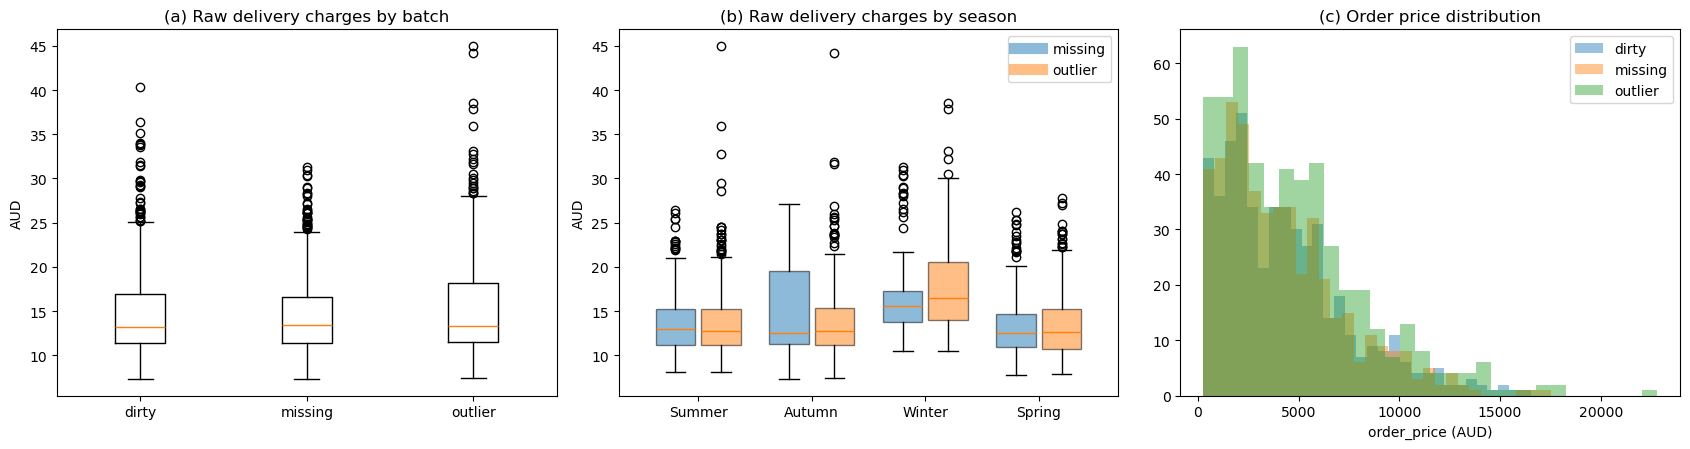

In [8]:
import matplotlib.pyplot as plt


def date_format_label(date_text):
    """Classify the textual format of one raw date value.

    Parameters
    ----------
    date_text : str
        Raw date cell from a source batch.
    """
    patterns = {
        "YYYY-MM-DD": r"\d{4}-\d{2}-\d{2}",
        "DD/MM/YYYY": r"\d{1,2}/\d{1,2}/\d{4}",
        "YYYY/MM/DD": r"\d{4}/\d{1,2}/\d{1,2}",
        "Mon DD, YYYY": r"[A-Za-z]{3} \d{1,2}, \d{4}",
    }
    for label, pattern in patterns.items():
        if re.fullmatch(pattern, str(date_text)):
            return label
    return "other"


print("Date representations")
display(pd.DataFrame({
    batch_name: dataframe["date"].map(date_format_label).value_counts()
    for batch_name, dataframe in source_batches.items()
}).fillna(0).astype(int))

numeric_columns = [
    "order_price", "delivery_charges", "order_total",
    "distance_to_nearest_warehouse", "customer_lat", "customer_long",
]
print("Numeric ranges (missing values excluded)")
display(pd.concat({
    batch_name: dataframe[numeric_columns].describe().T[["min", "25%", "50%", "75%", "max"]]
    for batch_name, dataframe in source_batches.items()
}).swaplevel().sort_index(level=0, sort_remaining=False).round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
batch_names = list(source_batches)
axes[0].boxplot([source_batches[name]["delivery_charges"].dropna() for name in batch_names],
                tick_labels=batch_names)
axes[0].set_title("(a) Raw delivery charges by batch")
axes[0].set_ylabel("AUD")

EDA_SEASONS = ["Summer", "Autumn", "Winter", "Spring"]
positions = np.arange(len(EDA_SEASONS))
for offset, (name, colour) in zip([-0.2, 0.2], [("missing", "tab:blue"), ("outlier", "tab:orange")]):
    frame = source_batches[name].dropna(subset=["season", "delivery_charges"])
    parts = axes[1].boxplot([frame.loc[frame["season"] == s, "delivery_charges"] for s in EDA_SEASONS],
                            positions=positions + offset, widths=0.35, patch_artist=True)
    for box in parts["boxes"]:
        box.set_facecolor(colour)
        box.set_alpha(0.5)
    axes[1].plot([], [], color=colour, linewidth=8, alpha=0.5, label=name)
axes[1].set_xticks(positions, EDA_SEASONS)
axes[1].set_title("(b) Raw delivery charges by season")
axes[1].set_ylabel("AUD")
axes[1].legend()

for name in batch_names:
    axes[2].hist(source_batches[name]["order_price"].dropna(), bins=30, alpha=0.45, label=name)
axes[2].set_title("(c) Order price distribution")
axes[2].set_xlabel("order_price (AUD)")
axes[2].legend()
plt.tight_layout()
plt.show()

**What the distributions show**

* **Dates.** All dates in the missing and outlier files use `YYYY-MM-DD` and are in 2019. The dirty
  file has 8 dates in other formats (day-first with slashes, year-first with slashes, and month
  names). These are format errors only. Using the day-first / year-first rule from the spec
  (1.0.4), each one can be read without any doubt, so in 1.1 we only change the format, not the
  actual date.
* **Coordinates.** In every file the longitudes are between 144.87 and 145.07, and almost all
  latitudes are between -37.89 and -37.74, which is the Melbourne area. However, the largest
  latitude in the dirty file is positive (+37.87). This looks like a sign error, which we check
  together with the warehouse and distance values in 1.0.9.
* **Distances.** All distances are between 0.1 and 11 km, which makes sense for three warehouses
  in Melbourne. The largest distance in the dirty file (10.98 km) is higher than in the other
  files (10.05 km), which suggests some distance values are wrong. 1.0.9 confirms this.
* **Delivery charges.** In all three files the charges are right-skewed, and Winter charges are
  higher than other seasons, which supports fitting a separate model for each season. The outlier
  file has a longer upper tail (up to AUD 44.98), but its middle 50% is almost the same as the
  clean missing file. So if we removed outliers using a raw cut-off value, we would miss wrong
  charges that look normal, and we would also delete expensive orders that are actually valid.
  Plot (a) shows this as well: even the clean missing file has many points above the 1.5×IQR
  line, and all of them are valid orders. This is why in 1.3 we use the residuals from the
  seasonal model instead of the raw charges.
* **Order prices.** Order prices are very right-skewed (from AUD 256 to about AUD 23,000). This is
  expected because unit prices range from about AUD 256 to AUD 4,404 (see 1.0.3), so it is not a
  sign of errors by itself.

**Which rows we can rely on.** In the outlier file, the carts and `order_price` values are
guaranteed to be correct, so we use them to work out the product prices (1.0.3). The complete rows
in the missing file do not break any rule (1.0.9), so we use them to train the delivery model
(Model A). We only use the dirty file for training after it has been repaired and checked
(Model B in 1.3).

### 1.0.2 Shopping-cart parsing

`shopping_cart` is JSON, even though the CSV representation contains doubled quotation marks.
The CSV reader restores the JSON string, and `json.loads` safely parses it. `eval` is not used.

The parser below also validates the expected object structure: each entry must contain a product
name and a positive integer quantity.

In [9]:
def parse_shopping_cart(cart_text):
    '''Parse and validate one shopping-cart JSON string.

    Parameters
    ----------
    cart_text : str
        JSON text containing a list of product and quantity objects.
    '''
    if not isinstance(cart_text, str):
        raise TypeError("shopping_cart must be supplied as text")

    parsed_cart = json.loads(cart_text)
    if not isinstance(parsed_cart, list) or len(parsed_cart) == 0:
        raise ValueError("shopping_cart must be a non-empty JSON list")

    for item in parsed_cart:
        if not isinstance(item, dict):
            raise ValueError("Every cart entry must be a JSON object")
        if set(item) != {"product", "quantity"}:
            raise ValueError("Every cart entry needs product and quantity keys")
        if not isinstance(item["product"], str) or not item["product"].strip():
            raise ValueError("Every product must have a non-empty text name")
        if isinstance(item["quantity"], bool) or not isinstance(item["quantity"], int):
            raise ValueError("Every quantity must be an integer")
        if item["quantity"] <= 0:
            raise ValueError("Every quantity must be positive")

    return parsed_cart

#### Cart-validation results

This cell applies the cart parser to every order and summarises product coverage, cart sizes and quantity ranges. Any malformed cart causes an explicit failure.

In [10]:
cart_summary_rows = []
all_product_names = set()

for batch_name, dataframe in source_batches.items():
    parsed_carts = []
    parsing_errors = []

    for row_index, cart_text in dataframe["shopping_cart"].items():
        try:
            parsed_carts.append(parse_shopping_cart(cart_text))
        except (TypeError, ValueError, json.JSONDecodeError) as error:
            parsing_errors.append((row_index, str(error)))

    cart_lengths = [len(cart) for cart in parsed_carts]
    quantities = [item["quantity"] for cart in parsed_carts for item in cart]
    batch_products = {
        item["product"] for cart in parsed_carts for item in cart
    }
    all_product_names.update(batch_products)

    cart_summary_rows.append(
        {
            "batch": batch_name,
            "parsing_errors": len(parsing_errors),
            "distinct_products": len(batch_products),
            "minimum_cart_lines": min(cart_lengths),
            "maximum_cart_lines": max(cart_lengths),
            "minimum_quantity": min(quantities),
            "maximum_quantity": max(quantities),
        }
    )
    assert len(parsing_errors) == 0

product_names = sorted(all_product_names)
assert len(product_names) == 12

display(pd.DataFrame(cart_summary_rows).set_index("batch"))
display(pd.DataFrame({"product": product_names}))
print("All shopping carts are valid JSON with positive integer quantities: PASS")

,parsing_errors,distinct_products,minimum_cart_lines,maximum_cart_lines,minimum_quantity,maximum_quantity
batch,,,,,,
dirty,0,12,1,5,1,3
missing,0,12,1,5,1,3
outlier,0,12,1,5,1,3


,product
0,Candle Edge 392
1,Candle Edge 932
2,Candle Flux 162
3,Candle Lumen 220
4,Candle Orbit 548
5,Candle Orbit 674
6,Candle Shift 916
7,Candle Vista 110
8,Vela Core 957
9,Vela Halo 137


All shopping carts are valid JSON with positive integer quantities: PASS


### 1.0.3 Current product-price inference

Each order price creates a linear equation: the quantity of each product multiplied by its
current unit price must sum to `order_price`. The outlier batch is suitable evidence because the
specification states that only `delivery_charges` can be anomalous there; its carts and order
prices are reliable.

A reproducible 80% subset is used to infer a provisional price vector. The remaining 20% is held
out to check that the prices reproduce unseen equations. Matrix rank must equal the number of
products, otherwise the equations do not uniquely identify every price. After validation, the
final price vector is refitted using all reliable outlier-batch equations.

In [11]:
def build_cart_matrix(dataframe, product_names):
    '''Build a product-quantity matrix from an order DataFrame.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Orders containing a shopping_cart column with JSON cart text.
    product_names : sequence of str
        Ordered product names defining the matrix columns.
    '''
    product_to_column = {
        product_name: column_index
        for column_index, product_name in enumerate(product_names)
    }
    quantity_matrix = np.zeros(
        (len(dataframe), len(product_names)),
        dtype=float,
    )

    for matrix_row, cart_text in enumerate(dataframe["shopping_cart"]):
        parsed_cart = parse_shopping_cart(cart_text)
        for item in parsed_cart:
            product_name = item["product"]
            if product_name not in product_to_column:
                raise ValueError(f"Unknown product in cart: {product_name}")
            matrix_column = product_to_column[product_name]
            quantity_matrix[matrix_row, matrix_column] += item["quantity"]

    return quantity_matrix


def infer_unit_prices(dataframe, product_names):
    '''Infer unit prices from reliable cart and order-price equations.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Reliable orders with complete shopping_cart and order_price values.
    product_names : sequence of str
        Ordered product names whose prices will be estimated.
    '''
    if dataframe["order_price"].isna().any():
        raise ValueError("Price inference requires complete order_price values")

    quantity_matrix = build_cart_matrix(dataframe, product_names)
    observed_order_prices = dataframe["order_price"].to_numpy(dtype=float)
    estimated_prices, residuals, matrix_rank, singular_values = np.linalg.lstsq(
        quantity_matrix,
        observed_order_prices,
        rcond=None,
    )

    if matrix_rank != len(product_names):
        raise ValueError(
            "The cart equations do not have full rank, so prices are not uniquely identified"
        )

    rounded_prices = np.round(estimated_prices, 2)
    price_series = pd.Series(
        rounded_prices,
        index=product_names,
        name="unit_price_aud",
    )
    diagnostics = {
        "number_of_equations": len(dataframe),
        "number_of_products": len(product_names),
        "matrix_rank": int(matrix_rank),
        "least_squares_residual_sum": (
            float(residuals[0]) if len(residuals) else 0.0
        ),
        "smallest_singular_value": float(singular_values.min()),
    }
    return price_series, diagnostics

#### Held-out price validation

This cell uses a reproducible split to infer provisional prices and test them on unused cart equations. It confirms that the price vector generalises beyond its fitting rows.

In [12]:
random_generator = np.random.default_rng(RANDOM_SEED)
shuffled_positions = random_generator.permutation(len(outlier_source))
training_size = int(0.80 * len(outlier_source))

training_positions = shuffled_positions[:training_size]
validation_positions = shuffled_positions[training_size:]
price_training_data = outlier_source.iloc[training_positions].copy(deep=True)
price_validation_data = outlier_source.iloc[validation_positions].copy(deep=True)

provisional_unit_prices, training_diagnostics = infer_unit_prices(
    price_training_data,
    product_names,
)

validation_cart_matrix = build_cart_matrix(
    price_validation_data,
    product_names,
)
validation_predictions = np.round(
    validation_cart_matrix @ provisional_unit_prices.to_numpy(),
    2,
)
validation_observed = price_validation_data["order_price"].to_numpy(dtype=float)
validation_absolute_errors = np.abs(
    validation_predictions - validation_observed
)

assert training_diagnostics["matrix_rank"] == len(product_names)
assert validation_absolute_errors.max() <= MONEY_TOLERANCE

display(pd.Series(training_diagnostics, name="training_diagnostic"))
display(
    pd.Series(
        {
            "held_out_equations": len(price_validation_data),
            "maximum_absolute_error_aud": validation_absolute_errors.max(),
            "mean_absolute_error_aud": validation_absolute_errors.mean(),
        },
        name="held_out_validation",
    )
)
print("Held-out cart-equation validation: PASS")

number_of_equations           4.000000e+02
number_of_products            1.200000e+01
matrix_rank                   1.200000e+01
least_squares_residual_sum    6.633966e-22
smallest_singular_value       9.212117e+00
Name: training_diagnostic, dtype: float64

held_out_equations            100.0
maximum_absolute_error_aud      0.0
mean_absolute_error_aud         0.0
Name: held_out_validation, dtype: float64

Held-out cart-equation validation: PASS


#### Final price vector and batch comparison

This cell refits prices on all reliable equations and compares calculated order prices with each batch. It reports inconsistencies but does not repair them.

In [13]:
final_unit_prices, final_price_diagnostics = infer_unit_prices(
    outlier_source,
    product_names,
)

display(final_unit_prices.to_frame())
display(pd.Series(final_price_diagnostics, name="final_fit_diagnostic"))

price_check_rows = []
for batch_name, dataframe in source_batches.items():
    observed_mask = dataframe["order_price"].notna()
    observed_orders = dataframe.loc[observed_mask]
    cart_matrix = build_cart_matrix(observed_orders, product_names)
    calculated_prices = np.round(
        cart_matrix @ final_unit_prices.to_numpy(),
        2,
    )
    observed_prices = observed_orders["order_price"].to_numpy(dtype=float)
    absolute_errors = np.abs(calculated_prices - observed_prices)

    price_check_rows.append(
        {
            "batch": batch_name,
            "observed_order_prices": len(observed_orders),
            "matches_within_0.01": int(
                (absolute_errors <= MONEY_TOLERANCE).sum()
            ),
            "values_to_investigate_later": int(
                (absolute_errors > MONEY_TOLERANCE).sum()
            ),
            "maximum_absolute_error_aud": absolute_errors.max(),
        }
    )

display(pd.DataFrame(price_check_rows).set_index("batch"))

,unit_price_aud
Candle Edge 392,375.75
Candle Edge 932,1490.48
Candle Flux 162,1060.29
Candle Lumen 220,3529.39
Candle Orbit 548,256.07
Candle Orbit 674,324.06
Candle Shift 916,1858.77
Candle Vista 110,1816.59
Vela Core 957,271.47
Vela Halo 137,759.89


number_of_equations           5.000000e+02
number_of_products            1.200000e+01
matrix_rank                   1.200000e+01
least_squares_residual_sum    1.367808e-21
smallest_singular_value       1.038364e+01
Name: final_fit_diagnostic, dtype: float64

,observed_order_prices,matches_within_0.01,values_to_investigate_later,maximum_absolute_error_aud
batch,,,,
dirty,500,492,8,121.75
missing,490,490,0,0.00
outlier,500,500,0,0.00


**What the price inference shows.** The 500 equations from the outlier file have full rank (12 out
of 12 products), so each product price can be worked out exactly, and the prices give zero error
on the held-out equations. When we apply these prices to the other files, every observed
`order_price` in the missing and outlier files is reproduced exactly. In the dirty file, a few rows
do not match (by up to about AUD 122). Since the carts are guaranteed to be correct, this means
these rows have a wrong `order_price`. In 1.1 we confirm this using `order_total` before fixing
them.

### 1.0.4 Reusable calculations for dates, seasons and order arithmetic

Dates may appear in year-first or slash-formatted day/month/year forms. The parser applies the
specification explicitly rather than asking pandas to guess. Seasons are then derived from the
calendar month using Australian seasons.

Order-price calculation follows the required item-level rounding. Order total applies the coupon
to merchandise only, adds delivery afterwards, and rounds the final result to two decimals.

In [14]:
def calculate_order_price(cart, unit_prices):
    '''Calculate a cart's merchandise price using the published rounding rule.

    Parameters
    ----------
    cart : str or list of dict
        Shopping-cart JSON text or an already parsed list of cart entries.
    unit_prices : mapping
        Mapping from each product name to its current unit price in AUD.
    '''
    parsed_cart = parse_shopping_cart(cart) if isinstance(cart, str) else cart
    item_amounts = []

    for item in parsed_cart:
        product_name = item["product"]
        if product_name not in unit_prices:
            raise KeyError(f"No unit price is available for {product_name}")
        item_amount = round(
            item["quantity"] * float(unit_prices[product_name]),
            2,
        )
        item_amounts.append(item_amount)

    return round(sum(item_amounts), 2)


def parse_order_date(date_value):
    '''Parse an order date using the explicit date rules.

    Parameters
    ----------
    date_value : str or date-like value
        Source order date. Slash-formatted numeric dates are day-first unless
        they begin with a four-digit year, which remains year-first.
    '''
    date_text = str(date_value).strip()

    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", date_text):
        return pd.to_datetime(date_text, format="%Y-%m-%d")
    if re.fullmatch(r"\d{4}/\d{2}/\d{2}", date_text):
        return pd.to_datetime(date_text, format="%Y/%m/%d")
    if re.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}", date_text):
        return pd.to_datetime(date_text, dayfirst=True)

    return pd.to_datetime(date_text, errors="raise")


def get_australian_season(order_date):
    '''Return the Australian season for an order date.

    Parameters
    ----------
    order_date : str or date-like value
        Order date whose calendar month determines the season.
    '''
    parsed_date = parse_order_date(order_date)
    month_number = parsed_date.month

    if month_number in (12, 1, 2):
        return "Summer"
    if month_number in (3, 4, 5):
        return "Autumn"
    if month_number in (6, 7, 8):
        return "Winter"
    return "Spring"


def calculate_order_total(order_price, coupon_discount, delivery_charge):
    '''Calculate the final order total using the published formula.

    Parameters
    ----------
    order_price : float
        Merchandise price before discount and delivery, in AUD.
    coupon_discount : float
        Percentage discount applied to merchandise only.
    delivery_charge : float
        Delivery charge added after the merchandise discount, in AUD.
    '''
    discounted_fraction = 1.0 - (float(coupon_discount) / 100.0)
    return round(
        float(order_price) * discounted_fraction + float(delivery_charge),
        2,
    )

#### Date and arithmetic function tests

This cell tests mixed date formats, season boundaries, cart pricing and the published order-total example before the functions are used for imputation.

In [15]:
assert parse_order_date("19/10/2019") == pd.Timestamp("2019-10-19")
assert parse_order_date("2019/11/09") == pd.Timestamp("2019-11-09")
assert parse_order_date("Apr 24, 2019") == pd.Timestamp("2019-04-24")

season_examples = {
    "2019-01-15": "Summer",
    "2019-03-01": "Autumn",
    "2019-06-30": "Winter",
    "2019-09-01": "Spring",
    "2019-12-31": "Summer",
}
for example_date, expected_season in season_examples.items():
    assert get_australian_season(example_date) == expected_season

assert calculate_order_total(100.00, 10, 8.00) == 98.00

example_cart = '[{"product":"Candle Edge 392","quantity":2}]'
expected_example_price = round(2 * final_unit_prices["Candle Edge 392"], 2)
assert calculate_order_price(example_cart, final_unit_prices) == expected_example_price
print("Date, season, order-price and order-total function tests: PASS")

Date, season, order-price and order-total function tests: PASS


### 1.0.5 Reusable warehouse and distance calculations

Customer-to-warehouse distance is the straight-line great-circle distance calculated with the
haversine formula and an Earth radius of 6,371 km. The nearest warehouse is the warehouse with
the minimum calculated distance. Road-routing data and shortest-path algorithms are not relevant.

Calculations retain coordinate precision; reconstructed distances are rounded to four decimals
only when returned for comparison or future repair.

In [16]:
def haversine_distance(lat1, lon1, lat2, lon2):
    '''Calculate great-circle distance between two coordinates in kilometres.

    Parameters
    ----------
    lat1 : float
        Latitude of the first point in decimal degrees.
    lon1 : float
        Longitude of the first point in decimal degrees.
    lat2 : float
        Latitude of the second point in decimal degrees.
    lon2 : float
        Longitude of the second point in decimal degrees.
    '''
    latitude_1 = math.radians(float(lat1))
    longitude_1 = math.radians(float(lon1))
    latitude_2 = math.radians(float(lat2))
    longitude_2 = math.radians(float(lon2))

    latitude_difference = latitude_2 - latitude_1
    longitude_difference = longitude_2 - longitude_1

    haversine_value = (
        math.sin(latitude_difference / 2.0) ** 2
        + math.cos(latitude_1)
        * math.cos(latitude_2)
        * math.sin(longitude_difference / 2.0) ** 2
    )
    central_angle = 2.0 * math.asin(math.sqrt(haversine_value))
    return EARTH_RADIUS_KM * central_angle


def find_nearest_warehouse(customer_lat, customer_long, warehouses):
    '''Find the closest supplied warehouse to a customer coordinate.

    Parameters
    ----------
    customer_lat : float
        Customer latitude in decimal degrees.
    customer_long : float
        Customer longitude in decimal degrees.
    warehouses : pandas.DataFrame
        Reference data containing warehouse, latitude and longitude columns.
    '''
    required_warehouse_columns = {"warehouse", "latitude", "longitude"}
    if not required_warehouse_columns.issubset(warehouses.columns):
        raise ValueError("Warehouse reference data has missing required columns")

    distances = []
    for warehouse_row in warehouses.itertuples(index=False):
        distance_km = haversine_distance(
            customer_lat,
            customer_long,
            warehouse_row.latitude,
            warehouse_row.longitude,
        )
        distances.append((warehouse_row.warehouse, distance_km))

    nearest_name, nearest_distance = min(
        distances,
        key=lambda warehouse_distance: warehouse_distance[1],
    )
    return nearest_name, round(nearest_distance, 4)

#### Warehouse function tests

This cell tests zero distance at each warehouse and demonstrates the nearest-warehouse calculation on a supplied order.

In [17]:
assert haversine_distance(-37.8, 145.0, -37.8, 145.0) == 0.0

for warehouse_row in warehouses_source.itertuples(index=False):
    calculated_name, calculated_distance = find_nearest_warehouse(
        warehouse_row.latitude,
        warehouse_row.longitude,
        warehouses_source,
    )
    assert calculated_name == warehouse_row.warehouse
    assert calculated_distance == 0.0

example_order = outlier_source.iloc[0]
example_warehouse, example_distance = find_nearest_warehouse(
    example_order["customer_lat"],
    example_order["customer_long"],
    warehouses_source,
)
print(f"Example calculated warehouse: {example_warehouse}")
print(f"Example calculated distance: {example_distance:.4f} km")
print("Haversine and nearest-warehouse function tests: PASS")

Example calculated warehouse: Nickolson
Example calculated distance: 7.2270 km
Haversine and nearest-warehouse function tests: PASS


### 1.0.6 Reusable VADER happiness classification

The supplied review must be scored exactly as written. A customer is happy when the VADER
compound score is greater than or equal to 0.05. The exact text `No review submitted` must return `True` without being treated as missing.

A small dummy analyser is used to test the inclusive boundary exactly. This avoids relying on a
particular sentence to happen to receive a compound score of precisely 0.05.

In [18]:
def classify_customer_happiness(review_text, analyser):
    '''Classify prior-review happiness using the assignment's VADER rule.

    Parameters
    ----------
    review_text : str
        Supplied English review text or the exact no-review sentinel.
    analyser : nltk.sentiment.vader.SentimentIntensityAnalyzer
        Configured sentiment analyser using the frozen local lexicon.
    '''
    if review_text == NO_REVIEW_SENTINEL:
        return True
    if not isinstance(review_text, str):
        raise TypeError("latest_customer_review must be text")

    compound_score = analyser.polarity_scores(review_text)["compound"]
    return bool(compound_score >= resource_contract["compound_threshold"])


class BoundaryTestAnalyser:
    '''Return a fixed compound score for an exact threshold test.'''

    def polarity_scores(self, review_text):
        '''Return a fixed VADER-like score dictionary.

        Parameters
        ----------
        review_text : str
            Review text accepted to match the real analyser interface.
        '''
        return {"compound": 0.05}


assert classify_customer_happiness(
    NO_REVIEW_SENTINEL,
    sentiment_analyser,
) is True
assert classify_customer_happiness(
    "Boundary test",
    BoundaryTestAnalyser(),
) is True
assert classify_customer_happiness(
    "This product is excellent and reliable.",
    sentiment_analyser,
) is True
assert classify_customer_happiness(
    "This product is terrible and disappointing.",
    sentiment_analyser,
) is False
print("VADER resource, sentinel and inclusive-threshold tests: PASS")

VADER resource, sentinel and inclusive-threshold tests: PASS


### 1.0.7 Foundation checks before cleaning

Here we recompute the file hashes and compare each source DataFrame with the copy we saved at the
start. If these checks pass, it means none of the investigation or function tests above changed
the original files or the source tables in memory. From this point on, all changes are made on
separate working copies.

We do not fix a value just because one related check fails. In sections 1.1 to 1.3 we use the
batch guarantees to decide which single field is actually wrong.

In [19]:
final_source_hashes = {
    source_name: sha256_file(source_path)
    for source_name, source_path in source_paths.items()
}
assert final_source_hashes == initial_source_hashes

for batch_name, source_dataframe in source_batches.items():
    pd.testing.assert_frame_equal(
        source_dataframe,
        source_snapshots[batch_name],
        check_dtype=True,
        check_exact=True,
    )

# Output files from an earlier run may already exist. They are recreated later in the notebook,
# so we only check that the raw input files have not changed.

final_summary = pd.Series(
    {
        "source_file_hashes_unchanged": True,
        "source_dataframes_unchanged": True,
        "batches_checked": len(source_batches),
        "distinct_order_ids": combined_order_ids.nunique(),
        "products_identified": len(product_names),
        "price_matrix_rank": final_price_diagnostics["matrix_rank"],
        "vader_contract_verified": True,
    },
    name="shared_foundation_result",
)
display(final_summary)

source_file_hashes_unchanged    True
source_dataframes_unchanged     True
batches_checked                    3
distinct_order_ids              1500
products_identified               12
price_matrix_rank                 12
vader_contract_verified         True
Name: shared_foundation_result, dtype: object

### 1.0.8 Shared audit, model and validation helpers

The next three cells define the helper functions that all three batches use, so every batch records
its changes and fits its seasonal models in the same way:

* `AUDIT_COLUMNS`, `format_audit_value` and the functions that record audit entries;
* the seasonal delivery-model functions;
* `record_validation_result`, which we use for every Task 2 check.

**Audit confidence levels** (used in the `confidence` column of `audit_log.csv`):

* **high:** the value comes from a fixed rule, or the model clearly supports one option;
* **medium:** the evidence supports the value, but there is still some uncertainty;
* **low:** the evidence is weak, or other possible values cannot be ruled out.

In [20]:
AUDIT_COLUMNS = [
    "source_file",
    "record_key",
    "field_name",
    "issue_type",
    "original_value",
    "corrected_value",
    "method",
    "evidence",
    "confidence",
]

missing_change_records = []


def format_audit_value(field_name, value):
    '''Format a corrected value for the future audit CSV.

    Parameters
    ----------
    field_name : str
        Name of the field whose corrected value is being formatted.
    value : object
        Corrected Python value to represent in the audit record.
    '''
    if field_name in {"order_price", "delivery_charges", "order_total"}:
        return f"{float(value):.2f}"
    if field_name == "distance_to_nearest_warehouse":
        return f"{float(value):.4f}"
    if field_name in {"is_expedited_delivery", "is_happy_customer"}:
        return "True" if bool(value) else "False"
    return str(value)


def record_missing_imputation(
    records,
    order_id,
    field_name,
    corrected_value,
    method,
    evidence,
    confidence="high",
):
    '''Append one missing-value imputation to an audit-record list.

    Parameters
    ----------
    records : list of dict
        Mutable list that collects audit records.
    order_id : str
        Stable order identifier for the affected record.
    field_name : str
        Name of the field whose missing value was recovered.
    corrected_value : object
        Recovered value written to the cleaned working copy.
    method : str
        Short description of the rule, calculation or model used.
    evidence : str
        Traceable notebook evidence supporting the imputation.
    confidence : str, default "high"
        Confidence level using the definitions stated above.
    '''
    if confidence not in {"high", "medium", "low"}:
        raise ValueError("confidence must be high, medium or low")

    records.append(
        {
            "source_file": MISSING_SOURCE_FILENAME,
            "record_key": str(order_id),
            "field_name": field_name,
            "issue_type": "missing",
            "original_value": "<MISSING>",
            "corrected_value": format_audit_value(field_name, corrected_value),
            "method": method,
            "evidence": evidence,
            "confidence": confidence,
        }
    )

In [21]:
DELIVERY_MODEL_COLUMNS = [
    "season",
    "delivery_charges",
    "distance_to_nearest_warehouse",
    "is_expedited_delivery",
    "is_happy_customer",
]
SEASON_ORDER = ["Summer", "Autumn", "Winter", "Spring"]


def build_delivery_design_matrix(dataframe, expedited_override=None):
    '''Build the delivery-model predictor matrix for a set of orders.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Orders containing distance, expedited and happiness predictors.
    expedited_override : bool or None, default None
        Optional Boolean used for every row instead of the stored expedited value.
    '''
    row_count = len(dataframe)
    intercept = np.ones(row_count, dtype=float)
    distance = dataframe["distance_to_nearest_warehouse"].to_numpy(dtype=float)

    if expedited_override is None:
        expedited = dataframe["is_expedited_delivery"].to_numpy(dtype=float)
    else:
        expedited = np.full(row_count, float(expedited_override), dtype=float)

    happiness = dataframe["is_happy_customer"].to_numpy(dtype=float)
    return np.column_stack([intercept, distance, expedited, happiness])


def fit_seasonal_delivery_model(season_data):
    '''Fit one season's linear delivery-charge model.

    Parameters
    ----------
    season_data : pandas.DataFrame
        Complete reliable orders belonging to one Australian season.
    '''
    if season_data[DELIVERY_MODEL_COLUMNS].isna().any().any():
        raise ValueError("Seasonal model data must be complete")

    design_matrix = build_delivery_design_matrix(season_data)
    observed_charges = season_data["delivery_charges"].to_numpy(dtype=float)
    coefficients, residuals, matrix_rank, singular_values = np.linalg.lstsq(
        design_matrix,
        observed_charges,
        rcond=None,
    )

    if matrix_rank != design_matrix.shape[1]:
        raise ValueError("Seasonal delivery-model predictors do not have full rank")

    return {
        "coefficients": coefficients,
        "matrix_rank": int(matrix_rank),
        "residual_sum": float(residuals[0]) if len(residuals) else 0.0,
        "smallest_singular_value": float(singular_values.min()),
    }


def predict_delivery_charges(dataframe, fitted_model, expedited_override=None):
    '''Predict delivery charges from a fitted seasonal model.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Orders containing the required model predictors.
    fitted_model : dict
        Model information returned by fit_seasonal_delivery_model.
    expedited_override : bool or None, default None
        Optional expedited value used instead of the stored column.
    '''
    design_matrix = build_delivery_design_matrix(dataframe,expedited_override=expedited_override)
    return design_matrix @ fitted_model["coefficients"]


def evaluate_seasonal_delivery_models(dataframe, random_seed):
    '''Evaluate and refit separate delivery models for all four seasons.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Missing-data batch containing reliable complete model rows.
    random_seed : int
        Seed used to create reproducible per-season 80/20 splits.
    '''
    eligible_data = dataframe.dropna(subset=DELIVERY_MODEL_COLUMNS).copy(deep=True)
    random_generator = np.random.default_rng(random_seed)
    metric_rows = []
    refitted_models = {}

    for season_name in SEASON_ORDER:
        season_data = eligible_data.loc[
            eligible_data["season"] == season_name
        ].copy(deep=True)
        shuffled_positions = random_generator.permutation(len(season_data))
        training_size = int(0.80 * len(season_data))
        training_data = season_data.iloc[shuffled_positions[:training_size]]
        testing_data = season_data.iloc[shuffled_positions[training_size:]]

        evaluation_model = fit_seasonal_delivery_model(training_data)
        predictions = predict_delivery_charges(testing_data, evaluation_model)
        observed = testing_data["delivery_charges"].to_numpy(dtype=float)
        residuals = observed - predictions
        total_variation = np.sum((observed - observed.mean()) ** 2)
        r_squared = 1.0 - (np.sum(residuals**2) / total_variation)
        mean_absolute_error = float(np.mean(np.abs(residuals)))

        metric_rows.append(
            {
                "season": season_name,
                "eligible_rows": len(season_data),
                "training_rows": len(training_data),
                "held_out_rows": len(testing_data),
                "r_squared": r_squared,
                "mean_absolute_error_aud": mean_absolute_error,
            }
        )
        refitted_models[season_name] = fit_seasonal_delivery_model(season_data)

    metrics = pd.DataFrame(metric_rows).set_index("season")
    return metrics, refitted_models, eligible_data


def infer_expedited_delivery(order_row, seasonal_models):
    '''Infer a missing expedited-delivery value using seasonal predictions.

    Parameters
    ----------
    order_row : pandas.Series
        One order with observed season, distance, happiness and delivery charge.
    seasonal_models : dict
        Mapping from season name to its refitted delivery model.
    '''
    season_name = order_row["season"]
    model = seasonal_models[season_name]
    one_row = order_row.to_frame().T

    predicted_false = float(
        predict_delivery_charges(one_row, model, expedited_override=False)[0]
    )
    predicted_true = float(
        predict_delivery_charges(one_row, model, expedited_override=True)[0]
    )
    observed_charge = float(order_row["delivery_charges"])
    false_residual = abs(observed_charge - predicted_false)
    true_residual = abs(observed_charge - predicted_true)
    selected_value = true_residual < false_residual
    selected_residual = min(false_residual, true_residual)
    alternative_residual = max(false_residual, true_residual)

    return {
        "selected_value": bool(selected_value),
        "predicted_if_false": predicted_false,
        "predicted_if_true": predicted_true,
        "residual_if_false": false_residual,
        "residual_if_true": true_residual,
        "selected_residual": selected_residual,
        "alternative_residual": alternative_residual,
        "residual_separation": alternative_residual - selected_residual,
    }

In [22]:
validation_results = []


def record_validation_result(
    results,
    check_id,
    check_name,
    observed_result,
    passed,
    interpretation,
):
    '''Append one executable validation result to a results list.

    Parameters
    ----------
    results : list of dict
        Mutable list collecting validation outcomes.
    check_id : str
        Short stable identifier used by audit evidence and notebook references.
    check_name : str
        Concise description of the condition being checked.
    observed_result : object
        Actual value or summary produced by the check.
    passed : bool
        Whether the observed result satisfies the requirement.
    interpretation : str
        Explanation of what the result establishes or how it was resolved.
    '''
    results.append(
        {
            "check_id": check_id,
            "check_name": check_name,
            "observed_result": str(observed_result),
            "status": "PASS" if bool(passed) else "FAIL",
            "interpretation": interpretation,
        }
    )

### 1.0.9 Rule-consistency profile of all three batches

Each derivable field is recomputed from the fields it depends on, using the shared functions:

* cart → `order_price`;
* date → `season`;
* coordinates → warehouse and distance;
* review → happiness;
* price, coupon and delivery → `order_total`.

Each disagreement is then flagged. A flag shows that **two fields disagree**. It does not say
which one is wrong. Attribution is made per batch, using the batch guarantees and independent
evidence (1.1 and 1.3). Missing source values are never counted as disagreements.

In [23]:
ISO_DATE_PATTERN = re.compile(r"\d{4}-\d{2}-\d{2}")
MELBOURNE_LAT_RANGE = (-38.6, -37.4)
MELBOURNE_LONG_RANGE = (144.4, 145.6)
VALID_WAREHOUSES = set(warehouses_source["warehouse"])


def in_melbourne(customer_lat, customer_long):
    """Return True when coordinates fall inside the Melbourne plausibility box.

    Parameters
    ----------
    customer_lat : float
        Latitude in decimal degrees.
    customer_long : float
        Longitude in decimal degrees.
    """
    return (MELBOURNE_LAT_RANGE[0] <= customer_lat <= MELBOURNE_LAT_RANGE[1]
            and MELBOURNE_LONG_RANGE[0] <= customer_long <= MELBOURNE_LONG_RANGE[1])


def derive_expected_values(dataframe):
    """Recompute every derivable field from the fields it depends on.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Orders in the published 16-column schema.
    """
    rows = []
    for row in dataframe.itertuples(index=False):
        parsed_date = parse_order_date(row.date)
        name, distance = find_nearest_warehouse(row.customer_lat, row.customer_long, warehouses_source)
        has_total_inputs = pd.notna(row.order_price) and pd.notna(row.delivery_charges)
        rows.append({
            "order_id": str(row.order_id),
            "calc_order_price": calculate_order_price(row.shopping_cart, final_unit_prices),
            "date_is_iso": isinstance(row.date, str) and bool(ISO_DATE_PATTERN.fullmatch(row.date)),
            "iso_date": parsed_date.strftime("%Y-%m-%d"),
            "calc_season": get_australian_season(row.date),
            "coords_in_melbourne": in_melbourne(row.customer_lat, row.customer_long),
            "calc_warehouse": name,
            "calc_distance": distance,
            "calc_happy": classify_customer_happiness(row.latest_customer_review, sentiment_analyser),
            "calc_total": (calculate_order_total(row.order_price, row.coupon_discount, row.delivery_charges)
                           if has_total_inputs else np.nan),
        })
    return pd.DataFrame(rows).set_index("order_id")


def flag_rule_violations(dataframe, expected):
    """Return one Boolean flag per published relationship (True = the two fields disagree).

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Orders in the published schema.
    expected : pandas.DataFrame
        Output of derive_expected_values for the same orders.
    """
    df = dataframe.set_index("order_id")
    df.index = df.index.astype(str)
    expected = expected.set_axis(expected.index.astype(str))
    observed = lambda column: df[column].notna()
    return pd.DataFrame({
        "price_vs_cart": observed("order_price")
            & ((df["order_price"] - expected["calc_order_price"]).abs() > MONEY_TOLERANCE),
        "date_not_iso": ~expected["date_is_iso"],
        "season_vs_date": observed("season") & (df["season"] != expected["calc_season"]),
        "coords_outside_melbourne": ~expected["coords_in_melbourne"],
        "warehouse_label_invalid": observed("nearest_warehouse") & ~df["nearest_warehouse"].isin(VALID_WAREHOUSES),
        "warehouse_vs_coords": observed("nearest_warehouse") & df["nearest_warehouse"].isin(VALID_WAREHOUSES)
            & (df["nearest_warehouse"] != expected["calc_warehouse"]),
        "distance_vs_coords": observed("distance_to_nearest_warehouse")
            & ((df["distance_to_nearest_warehouse"] - expected["calc_distance"]).abs() > DISTANCE_TOLERANCE),
        "happy_vs_review": observed("is_happy_customer")
            & (df["is_happy_customer"].astype(object) != expected["calc_happy"]),
        "total_vs_arithmetic": observed("order_total") & expected["calc_total"].notna()
            & ((df["order_total"] - expected["calc_total"]).abs() > MONEY_TOLERANCE),
    })


expected_by_batch = {name: derive_expected_values(df) for name, df in source_batches.items()}
flags_by_batch = {name: flag_rule_violations(df, expected_by_batch[name]) for name, df in source_batches.items()}
violation_summary = pd.DataFrame({name: flags.sum() for name, flags in flags_by_batch.items()})
violation_summary.loc["rows_with_any_flag"] = [int(f.any(axis=1).sum()) for f in flags_by_batch.values()]
display(violation_summary)

,dirty,missing,outlier
price_vs_cart,8,0,0
date_not_iso,8,0,0
season_vs_date,8,0,0
coords_outside_melbourne,8,0,0
warehouse_label_invalid,9,0,0
warehouse_vs_coords,3,0,0
distance_vs_coords,16,0,0
happy_vs_review,8,0,0
total_vs_arithmetic,24,0,25
rows_with_any_flag,73,0,25


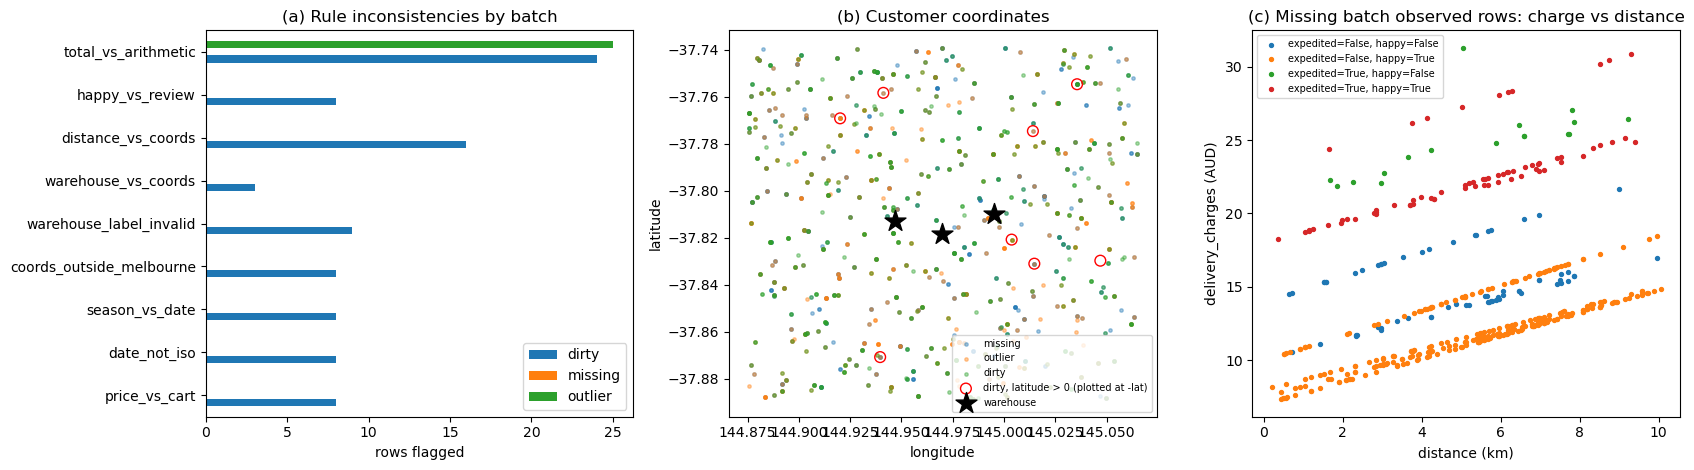

In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
violation_summary.drop("rows_with_any_flag").plot.barh(ax=axes[0])
axes[0].set_title("(a) Rule inconsistencies by batch")
axes[0].set_xlabel("rows flagged")

for batch_name in ["missing", "outlier", "dirty"]:
    df = source_batches[batch_name]
    southern = df["customer_lat"] < 0
    axes[1].scatter(df.loc[southern, "customer_long"], df.loc[southern, "customer_lat"], s=6, alpha=0.4,
                    label=batch_name)
flipped = dirty_source[dirty_source["customer_lat"] > 0]
axes[1].scatter(flipped["customer_long"], -flipped["customer_lat"], s=60, facecolors="none", edgecolors="red",
                label="dirty, latitude > 0 (plotted at -lat)")
axes[1].scatter(warehouses_source["longitude"], warehouses_source["latitude"], marker="*", s=250, c="black",
                label="warehouse")
axes[1].set_title("(b) Customer coordinates"); axes[1].set_xlabel("longitude"); axes[1].set_ylabel("latitude")
axes[1].legend(fontsize=7)

complete_missing = missing_source.dropna(subset=["season", "delivery_charges", "distance_to_nearest_warehouse",
                                                 "is_expedited_delivery", "is_happy_customer"])
for (expedited, happy), group in complete_missing.groupby(["is_expedited_delivery", "is_happy_customer"]):
    axes[2].scatter(group["distance_to_nearest_warehouse"], group["delivery_charges"], s=8,
                    label=f"expedited={expedited}, happy={happy}")
axes[2].set_title("(c) Missing batch observed rows: charge vs distance")
axes[2].set_xlabel("distance (km)"); axes[2].set_ylabel("delivery_charges (AUD)"); axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

**What the profile shows.**

* **Missing batch.** No observed value breaks any rule. This agrees with its guarantee and
  makes its complete rows clean training evidence.
* **Outlier batch.** The only flag is `total_vs_arithmetic`, on a small set of rows. Only
  `delivery_charges` can be anomalous in this batch, so these rows already point to altered
  charges. The removal decision in 1.3 is still made with the seasonal model; these flags are
  used only as corroboration.
* **Dirty batch.** Flags appear in every field family. Panel (b) shows customers with a
  positive (northern-hemisphere) latitude. Several rows carry two or three flags, but each row
  can hold at most one wrong field. Section 1.1 therefore attributes every flag pattern to a
  single root cause.
* **Panel (c).** The charge rises linearly with distance, in separate bands for expedited and
  unhappy orders. This is the seasonal structure that the delivery models fit.

### 1.0.10 Seasonal delivery Model A (independent witness)

Model A is fitted exactly as in the missing-data notebook (1.2.3). It is trained on the 450
missing-batch rows where every model field is observed, using the same seed and the same
per-season 80/20 held-out evaluation, so the coefficients are identical to that notebook's.

Model A never sees the dirty or outlier batches. That makes it an independent **witness** for
deciding which field of a dirty row is wrong. If a row's observed charge disagrees with what its
(independently derived) predictors imply, the disagreement is evidence about those predictors
or about the charge.

In [25]:
model_a_metrics, model_a, model_a_training = evaluate_seasonal_delivery_models(missing_source, RANDOM_SEED)
display(model_a_metrics.round(6))
display(pd.DataFrame({s: m["coefficients"] for s, m in model_a.items()},
                     index=["intercept", "distance", "expedited", "happy"]).T.round(4))
assert (model_a_metrics["r_squared"] >= 0.99).all()


def predict_charge(models, season, distance, expedited, happy):
    """Predict one delivery charge with the shared predict_delivery_charges helper.

    Parameters
    ----------
    models : dict
        Season name -> fitted model returned by fit_seasonal_delivery_model.
    season : str
        Season whose model is used.
    distance, expedited, happy : float, bool, bool
        Predictor values for the order.
    """
    one_row = pd.DataFrame({"distance_to_nearest_warehouse": [float(distance)],
                            "is_expedited_delivery": [bool(expedited)],
                            "is_happy_customer": [bool(happy)]})
    return float(predict_delivery_charges(one_row, models[season])[0])


def predict_batch(models, dataframe):
    """Vectorised seasonal predictions for every row of a DataFrame (aligned to its index).

    Parameters
    ----------
    models : dict
        Season name -> fitted model.
    dataframe : pandas.DataFrame
        Orders with season and the three predictors.
    """
    predictions = pd.Series(np.nan, index=dataframe.index)
    for season, model in models.items():
        mask = dataframe["season"] == season
        if mask.any():
            predictions[mask] = predict_delivery_charges(dataframe.loc[mask], model)
    return predictions


training_residual = model_a_training["delivery_charges"] - predict_batch(model_a, model_a_training)
MODEL_WITNESS_TOLERANCE = 0.05
smallest_single_field_effect = min(abs(m["coefficients"][3]) for m in model_a.values())
print(f"Max |residual| on Model A training rows: {training_residual.abs().max():.4f} AUD")
print(f"Witness tolerance: {MODEL_WITNESS_TOLERANCE:.2f} AUD; "
      f"smallest single-field effect (|happiness coefficient|): {smallest_single_field_effect:.2f} AUD")
assert training_residual.abs().max() < MODEL_WITNESS_TOLERANCE < smallest_single_field_effect

,eligible_rows,training_rows,held_out_rows,r_squared,mean_absolute_error_aud
season,,,,,
Summer,100,80,20,1.0,0.001974
Autumn,132,105,27,1.0,0.002608
Winter,109,87,22,1.0,0.002532
Spring,109,87,22,1.0,0.002193


,intercept,distance,expedited,happy
Summer,10.0012,0.6999,9.9996,-2.0009
Autumn,9.9998,0.7801,10.9998,-3.0008
Winter,14.0009,0.8500,12.9988,-4.0009
Spring,9.9998,0.7299,10.4992,-2.4991


Max |residual| on Model A training rows: 0.0055 AUD
Witness tolerance: 0.05 AUD; smallest single-field effect (|happiness coefficient|): 2.00 AUD


**Why a 0.05 AUD witness tolerance.**

* **Clean rows.** Their residuals are at most about half a cent, which is rounding to cents.
* **One wrong field.** A single wrong distance, expedited flag, happiness flag or charge moves
  the residual by at least the smallest coefficient, about AUD 2 for happiness.
* **The tolerance.** AUD 0.05 sits safely between these two scales. Decisions in 1.1 never rest
  on the exact value, because every competing explanation is compared directly by residual.

## 1.1 Dirty data - diagnose and repair

Each dirty row contains at most one intentionally wrong field. Even so, several checks can fail
together because of that one field. A sign-flipped latitude, for example, breaks the coordinate,
warehouse and distance checks. Each row's evidence is therefore computed **from fields that are
guaranteed or independently derivable**, not from the stored dependent fields:

* **Season** from the date, **happiness** from VADER on the guaranteed review, and **price**
  from the guaranteed cart and validated prices.
* **Distance** from the coordinates. `customer_long` is guaranteed. A latitude outside
  Melbourne is tested with its sign reversed, the only correction that can make it valid.
* **Witness residual:** observed charge minus the Model A prediction from those derived
  predictors. The stored expedited flag is used, because no other field can derive it.

Alternative residuals are also computed for each competing explanation: the stated season, the
stored distance and happiness, and a flipped expedited flag. They show which field explains a
disagreement. The implied charge, `total − cart_price × (1 − coupon/100)`, separates a wrong
total from a wrong charge.

In [26]:
DIRTY_SOURCE_FILENAME = DIRTY_INPUT.name
# Exact source text of every cell, used only to quote audit original values.
dirty_source_text = pd.read_csv(DIRTY_INPUT, dtype=str, keep_default_na=False).set_index("order_id")

dirty_indexed = dirty_source.set_index("order_id")
dirty_expected = expected_by_batch["dirty"]
dirty_flags = flags_by_batch["dirty"]

evidence_rows = []
for order_id, row in dirty_indexed.iterrows():
    exp = dirty_expected.loc[order_id]
    lat = row["customer_lat"]
    if not in_melbourne(lat, row["customer_long"]) and in_melbourne(-lat, row["customer_long"]):
        lat = -lat
    witness_warehouse, witness_distance = find_nearest_warehouse(lat, row["customer_long"], warehouses_source)
    expedited, charge = bool(row["is_expedited_delivery"]), row["delivery_charges"]
    predicted = predict_charge(model_a, exp["calc_season"], witness_distance, expedited, exp["calc_happy"])
    implied = round(row["order_total"] - exp["calc_order_price"] * (1 - row["coupon_discount"] / 100), 2)
    evidence_rows.append({
        "order_id": order_id,
        "witness_lat": lat,
        "witness_warehouse": witness_warehouse,
        "witness_distance": witness_distance,
        "predicted_charge": predicted,
        "residual": charge - predicted,
        "residual_if_expedited_flipped": charge - predict_charge(model_a, exp["calc_season"], witness_distance,
                                                                 not expedited, exp["calc_happy"]),
        "residual_with_stated_season": charge - predict_charge(model_a, row["season"], witness_distance,
                                                               expedited, exp["calc_happy"]),
        "residual_with_stored_distance": charge - predict_charge(model_a, exp["calc_season"],
                                                                 row["distance_to_nearest_warehouse"],
                                                                 expedited, exp["calc_happy"]),
        "residual_with_stored_happy": charge - predict_charge(model_a, exp["calc_season"], witness_distance,
                                                              expedited, bool(row["is_happy_customer"])),
        "implied_delivery": implied,
        "implied_minus_predicted": implied - predicted,
    })
dirty_evidence = pd.DataFrame(evidence_rows).set_index("order_id")

flag_count = dirty_flags.sum(axis=1)
print("Rows by number of rule flags:", flag_count.value_counts().sort_index().to_dict())
print("Rows with no rule flag but witness residual above tolerance:",
      int(((dirty_evidence["residual"].abs() > MODEL_WITNESS_TOLERANCE) & (flag_count == 0)).sum()))
display(dirty_flags[flag_count > 0].value_counts().rename("rows").to_frame())

Rows by number of rule flags: {0: 427, 1: 57, 2: 13, 3: 3}
Rows with no rule flag but witness residual above tolerance: 8


rows
price_vs_cart date_not_iso season_vs_date coords_outside_melbourne warehouse_label_invalid warehouse_vs_coords distance_vs_coords happy_vs_review total_vs_arithmetic      
False         False        False          False                    False                   False               False              False           True                   16
                                                                   True                    False               False              False           False                   9
                                                                   False                   False               False              True            False                   8
True          False        False          False                    False                   False               False              False           True                    8
False         False        False          False                    False                   False               True               False           False                   8
              True         False          False                    False                   False               False              False           False                   8
              False        True           False                    False                   False               False              False           False                   8
                           False          True                     False                   False               True               False           False                   5
                                                                                           True                True               False           False                   3

### 1.1.1 Decision rules: from evidence pattern to affected field

Each rule names one field to repair. It also states the independent confirmation that must
hold, and how dependent flags are explained without editing valid fields.

| Rule | Evidence pattern | Affected field and repair | Required confirmation |
|---|---|---|---|
| D1 | Date not `YYYY-MM-DD` but parses under the published day-first / year-first rule | `date` → ISO text | Stated season agrees with the parsed month |
| D2 | Latitude outside Melbourne, negated latitude inside | `customer_lat` → −lat | Stored warehouse **and** distance are reproduced exactly from the corrected coordinates. Their flags are consequences of the bad latitude and are not edited. |
| D3 | Warehouse label not in `warehouses.csv` | `nearest_warehouse` → computed name | Coordinates valid, stored distance matches, and the label is a spelling variant of that name |
| D4 | Valid label ≠ computed nearest, distance consistent | `nearest_warehouse` → computed name | Distance matches. (Implemented, but no rows in this batch.) |
| D5 | Distance ≠ haversine from valid coordinates, label consistent | `distance_to_nearest_warehouse` → computed | Witness ≈ 0 with computed distance, large with stored distance |
| D6 | Season ≠ season of the date | `season` → date season | Witness ≈ 0 with date season, above tolerance with stated season, so the date is the consistent field |
| D7 | Happiness ≠ VADER rule on the guaranteed review | `is_happy_customer` → VADER label | Witness ≈ 0 with VADER label, large with stored label |
| D8 | Order price ≠ cart price | `order_price` → cart price | Stored total satisfies the formula with the cart price. The total flag is a consequence and is not edited. |
| D9 | Total ≠ formula, price consistent, witness ≈ 0 | `order_total` → formula total | The charge fits the model, so it is valid |
| D10 | Total ≠ formula, price consistent, witness large | `delivery_charges` → implied charge | Implied charge agrees with the Model A prediction |
| D11 | All rules pass, witness large, ≈ 0 with expedited flipped | `is_expedited_delivery` → flipped | Expedited is the only predictor no rule can derive |

A row matching more than one rule is reported as a conflict. A row with a signal but no rule is
reported as unresolved. Neither kind of row is repaired.

In [27]:
from difflib import SequenceMatcher

tolerance = MODEL_WITNESS_TOLERANCE


def label_similarity(label, name):
    """Letters-only, lower-case similarity ratio used to describe warehouse label variants.

    Parameters
    ----------
    label : str
        Stored warehouse label.
    name : str
        Reference warehouse name.
    """
    clean = lambda text: re.sub(r"[^a-z]", "", str(text).lower())
    return SequenceMatcher(None, clean(label), clean(name)).ratio()


def diagnose_dirty_row(order_id):
    """Apply rules D1-D11 to one dirty row and return its findings (expected length 0 or 1).

    Parameters
    ----------
    order_id : str
        Order to diagnose.
    """
    row, exp = dirty_indexed.loc[order_id], dirty_expected.loc[order_id]
    flags, ev = dirty_flags.loc[order_id], dirty_evidence.loc[order_id]
    findings = []

    def add(rule, field, corrected, method, evidence, confidence="high"):
        findings.append({"rule": rule, "field_name": field, "corrected_value": corrected,
                         "method": method, "evidence": evidence, "confidence": confidence})

    if flags["date_not_iso"]:
        add("D1", "date", exp["iso_date"],
            "Parsed with the published date rule (day-first for D/M/Y; year-first kept) and written as YYYY-MM-DD",
            f"Section 1.1 D1; '{row['date']}' -> {exp['iso_date']}; stated season {row['season']} agrees",
            "high" if exp["calc_season"] == row["season"] else "medium")

    if flags["coords_outside_melbourne"]:
        if in_melbourne(ev["witness_lat"], row["customer_long"]):
            reproduces = (ev["witness_warehouse"] == row["nearest_warehouse"]
                          and abs(ev["witness_distance"] - row["distance_to_nearest_warehouse"]) <= DISTANCE_TOLERANCE)
            add("D2", "customer_lat", ev["witness_lat"],
                "Latitude sign restored (southern hemisphere); longitude is guaranteed correct",
                f"Section 1.1 D2; -lat reproduces stored {row['nearest_warehouse']} and "
                f"{row['distance_to_nearest_warehouse']} km exactly", "high" if reproduces else "medium")
    else:
        if flags["warehouse_label_invalid"]:
            best = max(VALID_WAREHOUSES, key=lambda name: label_similarity(row["nearest_warehouse"], name))
            add("D3", "nearest_warehouse", exp["calc_warehouse"],
                "Non-reference label replaced by the minimum-haversine warehouse name",
                f"Section 1.1 D3; '{row['nearest_warehouse']}' not in warehouses.csv; nearest = {exp['calc_warehouse']} "
                f"({exp['calc_distance']:.4f} km, matches stored distance); label similarity "
                f"{label_similarity(row['nearest_warehouse'], exp['calc_warehouse']):.2f}",
                "high" if (not flags["distance_vs_coords"] and best == exp["calc_warehouse"]) else "medium")
        elif flags["warehouse_vs_coords"] and not flags["distance_vs_coords"]:
            add("D4", "nearest_warehouse", exp["calc_warehouse"], "Minimum haversine distance to the supplied warehouses",
                f"Section 1.1 D4; stored distance matches {exp['calc_warehouse']}")
        if flags["distance_vs_coords"] and not flags["warehouse_vs_coords"]:
            add("D5", "distance_to_nearest_warehouse", exp["calc_distance"],
                "Minimum haversine distance using Earth radius 6,371 km",
                f"Section 1.1 D5; stored {row['distance_to_nearest_warehouse']} vs computed {exp['calc_distance']:.4f}; "
                f"witness residual {ev['residual']:+.3f} (computed) vs {ev['residual_with_stored_distance']:+.3f} (stored)",
                "high" if abs(ev["residual"]) <= tolerance < abs(ev["residual_with_stored_distance"]) else "medium")

    if flags["season_vs_date"] and abs(ev["residual"]) <= tolerance < abs(ev["residual_with_stated_season"]):
        add("D6", "season", exp["calc_season"], "Australian season derived from the order-date month",
            f"Section 1.1 D6; date {row['date']} -> {exp['calc_season']}; witness residual {ev['residual']:+.3f} "
            f"(date season) vs {ev['residual_with_stated_season']:+.3f} (stated {row['season']})",
            "high" if abs(ev["residual_with_stated_season"]) >= 1.0 else "medium")

    if flags["happy_vs_review"]:
        add("D7", "is_happy_customer", bool(exp["calc_happy"]),
            "Frozen local VADER compound score with threshold >= 0.05",
            f"Section 1.1 D7; compound {sentiment_analyser.polarity_scores(row['latest_customer_review'])['compound']:+.4f}; "
            f"witness residual {ev['residual']:+.3f} (VADER) vs {ev['residual_with_stored_happy']:+.3f} (stored)",
            "high" if abs(ev["residual"]) <= tolerance < abs(ev["residual_with_stored_happy"]) else "medium")

    if flags["price_vs_cart"]:
        total_agrees = abs(calculate_order_total(exp["calc_order_price"], row["coupon_discount"],
                                                 row["delivery_charges"]) - row["order_total"]) <= MONEY_TOLERANCE
        add("D8", "order_price", exp["calc_order_price"],
            "Parsed cart quantities multiplied by validated current unit prices",
            f"Section 1.1 D8; stored {row['order_price']} vs cart {exp['calc_order_price']:.2f}; stored total "
            f"{'agrees' if total_agrees else 'does not agree'} with cart price", "high" if total_agrees else "medium")
    elif flags["total_vs_arithmetic"]:
        if abs(ev["residual"]) <= tolerance:
            add("D9", "order_total", exp["calc_total"], "Published discount and delivery arithmetic",
                f"Section 1.1 D9; stored {row['order_total']} vs {exp['calc_total']:.2f}; charge fits Model A "
                f"(residual {ev['residual']:+.3f})")
        elif abs(ev["implied_minus_predicted"]) <= tolerance:
            add("D10", "delivery_charges", ev["implied_delivery"], "Rearranged published order-total equation",
                f"Section 1.1 D10; stored charge residual {ev['residual']:+.3f}; implied {ev['implied_delivery']:.2f} "
                f"vs Model A {ev['predicted_charge']:.3f}")

    if not findings and abs(ev["residual"]) > tolerance and abs(ev["residual_if_expedited_flipped"]) <= tolerance:
        add("D11", "is_expedited_delivery", not bool(row["is_expedited_delivery"]),
            "Boolean option with the smaller seasonal delivery-model residual",
            f"Section 1.1 D11; residual {ev['residual']:+.3f} (stored {row['is_expedited_delivery']}) vs "
            f"{ev['residual_if_expedited_flipped']:+.3f} (flipped)")
    return findings


dirty_findings, conflicts, unresolved = [], [], []
for order_id in dirty_indexed.index:
    row_findings = diagnose_dirty_row(order_id)
    if len(row_findings) > 1:
        conflicts.append((order_id, [f["rule"] for f in row_findings]))
    dirty_findings.extend({"order_id": order_id, **f} for f in row_findings)
    has_signal = dirty_flags.loc[order_id].any() or abs(dirty_evidence.at[order_id, "residual"]) > tolerance
    if has_signal and not row_findings:
        unresolved.append(order_id)

dirty_findings = pd.DataFrame(dirty_findings)
print(f"Rows with exactly one finding: {dirty_findings['order_id'].nunique()}; "
      f"conflicts: {conflicts}; unresolved: {unresolved}")
assert not conflicts and not unresolved
display(dirty_findings.groupby(["rule", "field_name"]).agg(
    rows=("order_id", "size"),
    high=("confidence", lambda c: int((c == "high").sum())),
    medium=("confidence", lambda c: int((c == "medium").sum()))))

Rows with exactly one finding: 81; conflicts: []; unresolved: []


,,rows,high,medium
rule,field_name,,,
D1,date,8,8,0
D10,delivery_charges,8,8,0
D11,is_expedited_delivery,8,8,0
D2,customer_lat,8,8,0
D3,nearest_warehouse,9,9,0
D5,distance_to_nearest_warehouse,8,8,0
D6,season,8,4,4
D7,is_happy_customer,8,8,0
D8,order_price,8,8,0


**How the dependent checks were resolved.**

* **D2 rows.** These fail the coordinate, warehouse and distance checks together. Once the
  latitude is negated, the *stored* warehouse and distance are reproduced exactly. Both are
  correct and are left unchanged.
* **D8 rows.** These also fail the total check. The stored total agrees with the cart price,
  so the total is valid and only the price is repaired.
* **Total checks (D9/D10).** A total failure alone cannot say whether the total or the charge
  is wrong. The witness separates the two cleanly. In D9 rows the charge fits the model. In D10
  rows the charge is off-model, while the charge implied by the stored total matches the model
  to within a cent.
* **Season vs date (D6).** For a few rows, swapping day and month in the date would also give
  the stated season. In every case the *date's* season fits the charge and the stated season
  does not, so the season is repaired and the date is kept. Rows where the two seasons'
  predictions differ by less than AUD 1 are marked `medium`.

All findings and their evidence:

In [28]:
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 120, "display.width", 200):
    display(dirty_findings.assign(
        original=[dirty_source_text.at[o, f] for o, f in zip(dirty_findings["order_id"], dirty_findings["field_name"])],
        corrected=[format_audit_value(f, v) for f, v in zip(dirty_findings["field_name"], dirty_findings["corrected_value"])],
    )[["order_id", "rule", "field_name", "original", "corrected", "confidence", "evidence"]]
      .sort_values(["rule", "order_id"]).reset_index(drop=True))

,order_id,rule,field_name,original,corrected,confidence,evidence
0,CORD000047,D1,date,"Apr 24, 2019",2019-04-24,high,"Section 1.1 D1; 'Apr 24, 2019' -> 2019-04-24; stated season Autumn agrees"
1,CORD000054,D1,date,19/10/2019,2019-10-19,high,Section 1.1 D1; '19/10/2019' -> 2019-10-19; stated season Spring agrees
2,CORD000077,D1,date,"Jul 31, 2019",2019-07-31,high,"Section 1.1 D1; 'Jul 31, 2019' -> 2019-07-31; stated season Winter agrees"
3,CORD000147,D1,date,30/06/2019,2019-06-30,high,Section 1.1 D1; '30/06/2019' -> 2019-06-30; stated season Winter agrees
4,CORD000199,D1,date,2019/03/17,2019-03-17,high,Section 1.1 D1; '2019/03/17' -> 2019-03-17; stated season Autumn agrees
5,CORD000385,D1,date,2019/11/09,2019-11-09,high,Section 1.1 D1; '2019/11/09' -> 2019-11-09; stated season Spring agrees
6,CORD000469,D1,date,2019/01/10,2019-01-10,high,Section 1.1 D1; '2019/01/10' -> 2019-01-10; stated season Summer agrees
7,CORD000498,D1,date,30/07/2019,2019-07-30,high,Section 1.1 D1; '30/07/2019' -> 2019-07-30; stated season Winter agrees
8,CORD000044,D10,delivery_charges,35.17,11.42,high,Section 1.1 D10; stored charge residual +23.747; implied 11.42 vs Model A 11.423
9,CORD000111,D10,delivery_charges,33.97,26.72,high,Section 1.1 D10; stored charge residual +7.248; implied 26.72 vs Model A 26.722


### 1.1.2 Apply repairs and record audit evidence

Repairs are written to a deep copy, changing only the identified field in each row. Each
write appends its audit record through `record_dirty_repair`. That function follows the same
pattern as `record_missing_imputation`, except that the original value is quoted from the raw
source text instead of `<MISSING>`. The repaired batch is then re-profiled with the same rule
functions and witness.

In [29]:
dirty_change_records = []


def record_dirty_repair(records, order_id, field_name, corrected_value, method, evidence, confidence="high"):
    """Append one dirty-field repair to an audit-record list (final Task 2 column order).

    Parameters
    ----------
    records : list of dict
        Mutable list that collects audit records.
    order_id : str
        Stable order identifier for the affected record.
    field_name : str
        Name of the repaired field.
    corrected_value : object
        Value written to the cleaned working copy.
    method : str
        Short description of the rule or calculation used.
    evidence : str
        Traceable notebook evidence supporting the repair.
    confidence : str, default "high"
        Confidence level using the definitions in 1.0.8.
    """
    if confidence not in {"high", "medium", "low"}:
        raise ValueError("confidence must be high, medium or low")
    records.append({
        "source_file": DIRTY_SOURCE_FILENAME,
        "record_key": str(order_id),
        "field_name": field_name,
        "issue_type": "dirty",
        "original_value": dirty_source_text.at[order_id, field_name],
        "corrected_value": format_audit_value(field_name, corrected_value),
        "method": method,
        "evidence": evidence,
        "confidence": confidence,
    })


dirty_clean = dirty_source.copy(deep=True)
position_of = {order_id: position for position, order_id in enumerate(dirty_clean["order_id"])}
for finding in dirty_findings.itertuples(index=False):
    value = finding.corrected_value
    if finding.field_name in {"order_price", "delivery_charges", "order_total"}:
        value = round(float(value), 2)
    elif finding.field_name == "distance_to_nearest_warehouse":
        value = round(float(value), 4)
    elif finding.field_name in {"is_expedited_delivery", "is_happy_customer"}:
        value = bool(value)
    dirty_clean.iloc[position_of[finding.order_id], dirty_clean.columns.get_loc(finding.field_name)] = value
    record_dirty_repair(dirty_change_records, finding.order_id, finding.field_name, value,
                        finding.method, finding.evidence, finding.confidence)

repaired_flags = flag_rule_violations(dirty_clean, derive_expected_values(dirty_clean))
repaired_residual = dirty_clean["delivery_charges"] - predict_batch(model_a, dirty_clean)
cell_changes = dirty_clean.astype(str) != dirty_source.astype(str)
dirty_post_check = pd.Series({
    "rule flags remaining": int(repaired_flags.to_numpy().sum()),
    "max |Model A residual| (AUD)": round(float(repaired_residual.abs().max()), 4),
    "cells changed": int(cell_changes.to_numpy().sum()),
    "audit records": len(dirty_change_records),
    "rows changed": int(cell_changes.any(axis=1).sum()),
    "max cells changed in one row": int(cell_changes.sum(axis=1).max()),
    "order IDs retained": dirty_clean["order_id"].nunique(),
}, name="dirty_after_repair")
display(dirty_post_check.to_frame())
assert dirty_post_check["rule flags remaining"] == 0
assert dirty_post_check["max |Model A residual| (AUD)"] <= MODEL_WITNESS_TOLERANCE
assert dirty_post_check["cells changed"] == len(dirty_change_records) == len(dirty_findings)
assert dirty_post_check["max cells changed in one row"] == 1

,dirty_after_repair
rule flags remaining,0.0000
max |Model A residual| (AUD),0.0056
cells changed,81.0000
audit records,81.0000
rows changed,81.0000
max cells changed in one row,1.0000
order IDs retained,500.0000


**Result.**

* **Repairs.** 81 fields are repaired in 81 different rows, one field per row, which is
  consistent with the batch guarantee.
* **Re-check.** The repaired batch passes every published rule. Every row now fits Model A to
  within the witness tolerance; Model A never saw this batch, so this is independent evidence.
* **Retention.** All 500 order IDs are retained, and the other 7,919 cells are unchanged.
* **Limitation.** Repairs D1-D10 are deterministic, and each is confirmed by a second
  relationship. The expedited repairs (D11) rely on the model alone. They are still clearly
  separated: residual ≈ 0, against about AUD 10-13 for the alternative.

In [30]:
assert dirty_clean.isna().sum().sum() == 0
assert len(dirty_clean) == EXPECTED_ROWS_PER_BATCH
assert list(dirty_clean.columns) == EXPECTED_COLUMNS
assert dirty_clean["order_id"].is_unique and set(dirty_clean["order_id"]) == set(dirty_source["order_id"])
dirty_clean.to_csv(DIRTY_OUTPUT, index=False, encoding="utf-8", columns=EXPECTED_COLUMNS)
print(f"Created {DIRTY_OUTPUT} with {len(dirty_clean)} rows.")

Created Group018_dirty_clean.csv with 500 rows.


## 1.2 Missing data - recover omitted values

This section recovers only the empty fields in the missing-data batch. The specification
guarantees that every observed value in this batch is correct, so the workflow starts from a
deep copy and writes only to cells that were empty in the source.

Deterministic business relationships are preferred wherever they are available. The missing
expedited-delivery values are the only exception: they are inferred by comparing seasonal
delivery-model predictions under the two possible Boolean values.

In [31]:
MISSING_SOURCE_FILENAME = MISSING_INPUT.name

missing_clean = missing_source.copy(deep=True)
original_missing_mask = missing_source.isna()
missing_cells_per_row = original_missing_mask.sum(axis=1)

missing_counts_before = original_missing_mask.sum()
missing_counts_before = missing_counts_before[missing_counts_before > 0]

assert int(original_missing_mask.sum().sum()) == 81
assert int((missing_cells_per_row > 0).sum()) == 81
assert int(missing_cells_per_row.max()) == 1

display(missing_counts_before.rename("missing_cells").to_frame())
print("The source contains 81 missing cells across 81 separate rows: PASS")

,missing_cells
nearest_warehouse,11
order_price,10
delivery_charges,10
order_total,10
season,10
is_expedited_delivery,10
distance_to_nearest_warehouse,10
is_happy_customer,10


The source contains 81 missing cells across 81 separate rows: PASS


### 1.2.1 Recording the audit entries

Each missing value is recorded with `record_missing_imputation` (defined in 1.0.8) at the same time
as it is filled in. Every record uses the final audit column order, with
`original_value = <MISSING>` and `issue_type = missing`. The confidence levels are defined in 1.0.8.

### 1.2.2 Seasonal delivery models

The model functions are defined once in 1.0.8. We only train on rows from the missing file where
all the model columns are filled in (450 rows that are guaranteed to be correct), so imputed values
are never used to train the model.

### 1.2.3 Held-out delivery-model evaluation

This cell evaluates each season on observations that were not used to fit that evaluation model.
It reports eligible, training and held-out sample sizes together with R-squared and mean absolute
error. A clean seasonal relationship should produce R-squared of at least 0.99, but the error
measure is also reported because R-squared alone is not sufficient evidence.

After evaluation, each model is refitted on all eligible rows from its season for the final
expedited-delivery inference.

In [32]:
delivery_model_metrics, seasonal_delivery_models, delivery_model_training_data = (
    evaluate_seasonal_delivery_models(missing_source, RANDOM_SEED)
)

assert len(delivery_model_training_data) == 450
assert (delivery_model_metrics["r_squared"] >= 0.99).all()

display(delivery_model_metrics.round(6))

coefficient_rows = []
for season_name, fitted_model in seasonal_delivery_models.items():
    coefficients = fitted_model["coefficients"]
    coefficient_rows.append(
        {
            "season": season_name,
            "intercept": coefficients[0],
            "distance_coefficient": coefficients[1],
            "expedited_coefficient": coefficients[2],
            "happiness_coefficient": coefficients[3],
        }
    )

seasonal_model_coefficients = pd.DataFrame(coefficient_rows).set_index("season")
display(seasonal_model_coefficients.round(6))
print("Per-season held-out R-squared and absolute-error checks: PASS")

,eligible_rows,training_rows,held_out_rows,r_squared,mean_absolute_error_aud
season,,,,,
Summer,100,80,20,1.0,0.001974
Autumn,132,105,27,1.0,0.002608
Winter,109,87,22,1.0,0.002532
Spring,109,87,22,1.0,0.002193


,intercept,distance_coefficient,expedited_coefficient,happiness_coefficient
season,,,,
Summer,10.001157,0.699945,9.999641,-2.000917
Autumn,9.999833,0.780117,10.999774,-3.000815
Winter,14.000939,0.850047,12.998775,-4.000947
Spring,9.999771,0.729938,10.499179,-2.499145


Per-season held-out R-squared and absolute-error checks: PASS


### 1.2.4 Warehouse names and distances

This cell fills a missing warehouse name by selecting the smallest haversine distance from the
customer's coordinates. A missing distance uses the same calculation and retains four decimal
places. Only the missing target field is written, even though the helper returns both results.

In [33]:
# Impute missing nearest warehouse name
for row_index in missing_source.index[missing_source["nearest_warehouse"].isna()]:
    source_row = missing_source.loc[row_index]
    nearest_name, nearest_distance = find_nearest_warehouse(
        source_row["customer_lat"],
        source_row["customer_long"],
        warehouses_source,
    )
    missing_clean.at[row_index, "nearest_warehouse"] = nearest_name 
    record_missing_imputation(
        missing_change_records,
        source_row["order_id"],
        "nearest_warehouse",
        nearest_name,
        "Minimum haversine distance to the supplied warehouses",
        f"Section 1.2.4; calculated distance {nearest_distance:.4f} km",
    )
# Impute missing warehouse distance
for row_index in missing_source.index[
    missing_source["distance_to_nearest_warehouse"].isna()
]:
    source_row = missing_source.loc[row_index]
    nearest_name, nearest_distance = find_nearest_warehouse(
        source_row["customer_lat"],
        source_row["customer_long"],
        warehouses_source,
    )
    assert nearest_name == source_row["nearest_warehouse"]
    missing_clean.at[row_index, "distance_to_nearest_warehouse"] = nearest_distance 
    record_missing_imputation(
        missing_change_records,
        source_row["order_id"],
        "distance_to_nearest_warehouse",
        nearest_distance,
        "Minimum haversine distance using Earth radius 6,371 km",
        f"Section 1.2.4; nearest warehouse {nearest_name}",
    )

print("Warehouse names filled:", int(missing_source["nearest_warehouse"].isna().sum()))
print(
    "Warehouse distances filled:",
    int(missing_source["distance_to_nearest_warehouse"].isna().sum()),
)

Warehouse names filled: 11
Warehouse distances filled: 10


### 1.2.5 Merchandise prices

This cell calculates every missing `order_price` from its parsed shopping cart and the validated
current unit-price vector. It follows the required item-level rounding before summing the order.
The observed cart and inferred price vector are not altered.

In [34]:
for row_index in missing_source.index[missing_source["order_price"].isna()]:
    source_row = missing_source.loc[row_index]
    calculated_price = calculate_order_price(
        source_row["shopping_cart"],
        final_unit_prices,
    )
    missing_clean.at[row_index, "order_price"] = calculated_price
    record_missing_imputation(
        missing_change_records,
        source_row["order_id"],
        "order_price",
        calculated_price,
        "Parsed cart quantities multiplied by validated current unit prices",
        "Section 1.2.5; held-out price-vector validation passed",
    )

print("Order prices filled:", int(missing_source["order_price"].isna().sum()))

Order prices filled: 10


### 1.2.6 Delivery charges and order totals

This cell uses the published arithmetic relationship in both directions. A missing delivery charge
is isolated from the observed total, price and discount. A missing total is calculated by applying
the discount to merchandise only and adding delivery afterwards.

These deterministic relationships are preferred to model estimates because they use exact values
from the same order. Reconstructed monetary values are rounded to two decimal places.

In [35]:
for row_index in missing_source.index[missing_source["delivery_charges"].isna()]:
    source_row = missing_source.loc[row_index]
    discounted_fraction = 1.0 - (float(source_row["coupon_discount"]) / 100.0)
    calculated_delivery = round(
        float(source_row["order_total"])
        - float(source_row["order_price"]) * discounted_fraction,
        2,
    )
    missing_clean.at[row_index, "delivery_charges"] = calculated_delivery

    # Verify that the calculated delivery charge is accurate
    recalculated_total = calculate_order_total(
        source_row["order_price"],
        source_row["coupon_discount"],
        calculated_delivery,
    )
    assert abs(recalculated_total - source_row["order_total"]) <= MONEY_TOLERANCE

    record_missing_imputation(
        missing_change_records,
        source_row["order_id"],
        "delivery_charges",
        calculated_delivery,
        "Rearranged published order-total equation",
        "Section 1.2.6; forward total recalculation within AUD 0.01",
    )

for row_index in missing_source.index[missing_source["order_total"].isna()]:
    source_row = missing_source.loc[row_index]
    calculated_total = calculate_order_total(
        source_row["order_price"],
        source_row["coupon_discount"],
        source_row["delivery_charges"],
    )
    missing_clean.at[row_index, "order_total"] = calculated_total
    record_missing_imputation(
        missing_change_records,
        source_row["order_id"],
        "order_total",
        calculated_total,
        "Published discount and delivery arithmetic",
        "Section 1.2.6; coupon applied to merchandise only",
    )

print(
    "Delivery charges filled:",
    int(missing_source["delivery_charges"].isna().sum()),
)
print("Order totals filled:", int(missing_source["order_total"].isna().sum()))

Delivery charges filled: 10
Order totals filled: 10


### 1.2.7 Calendar seasons

This cell derives each missing season from the parsed order date. It uses Australian calendar
seasons, so December to February is Summer, March to May is Autumn, June to August is Winter,
and September to November is Spring.

In [36]:
for row_index in missing_source.index[missing_source["season"].isna()]:
    source_row = missing_source.loc[row_index]
    calculated_season = get_australian_season(source_row["date"])
    missing_clean.at[row_index, "season"] = calculated_season
    record_missing_imputation(
        missing_change_records,
        source_row["order_id"],
        "season",
        calculated_season,
        "Australian season derived from the order-date month",
        f"Section 1.2.7; source date {source_row['date']}",
    )

print("Seasons filled:", int(missing_source["season"].isna().sum()))

Seasons filled: 10


### 1.2.8 Customer happiness

This cell applies the checksum-verified local VADER analyser to the supplied review text exactly
as written. A compound score of at least 0.05 is happy, while the exact no-review sentinel is
treated as happy without being imputed or rewritten.

In [37]:
for row_index in missing_source.index[missing_source["is_happy_customer"].isna()]:
    source_row = missing_source.loc[row_index]
    calculated_happiness = classify_customer_happiness(
        source_row["latest_customer_review"],
        sentiment_analyser,
    )
    missing_clean.at[row_index, "is_happy_customer"] = calculated_happiness
    record_missing_imputation(
        missing_change_records,
        source_row["order_id"],
        "is_happy_customer",
        calculated_happiness,
        "Frozen local VADER compound score with threshold >= 0.05",
        "Section 1.2.8; resource checksum and NLTK version verified",
    )

print(
    "Happiness values filled:",
    int(missing_source["is_happy_customer"].isna().sum()),
)

Happiness values filled: 10


### 1.2.9 Expedited-delivery status

This cell evaluates each missing Boolean twice: once as non-expedited and once as expedited. The
seasonal model predicts the delivery charge for both possibilities, and the value with the smaller
absolute residual is selected.

The diagnostic table retains both predictions and residuals. A selection receives high confidence
only when its residual is within the delivery-charge tolerance and the alternative is separated by
at least AUD 1.00. Otherwise the record remains visible with lower confidence rather than being
presented as certain.

In [38]:
expedited_diagnostic_rows = []

for row_index in missing_source.index[
    missing_source["is_expedited_delivery"].isna()
]:
    source_row = missing_source.loc[row_index]
    diagnostics = infer_expedited_delivery(
        source_row,
        seasonal_delivery_models,
    )
    selected_value = diagnostics["selected_value"]

    if (
        diagnostics["selected_residual"] <= 0.08
        and diagnostics["residual_separation"] >= 1.00
    ):
        confidence = "high"
    elif diagnostics["selected_residual"] <= 0.50:
        confidence = "medium"
    else:
        confidence = "low"

    missing_clean.at[row_index, "is_expedited_delivery"] = selected_value
    record_missing_imputation(
        missing_change_records,
        source_row["order_id"],
        "is_expedited_delivery",
        selected_value,
        "Boolean option with the smaller seasonal delivery-model residual",
        (
            "Section 1.2.9; selected residual "
            f"{diagnostics['selected_residual']:.4f}, alternative residual "
            f"{diagnostics['alternative_residual']:.4f}"
        ),
        confidence=confidence,
    )

    expedited_diagnostic_rows.append(
        {
            "order_id": source_row["order_id"],
            "season": source_row["season"],
            "observed_delivery_charge": source_row["delivery_charges"],
            "predicted_if_false": diagnostics["predicted_if_false"],
            "predicted_if_true": diagnostics["predicted_if_true"],
            "residual_if_false": diagnostics["residual_if_false"],
            "residual_if_true": diagnostics["residual_if_true"],
            "selected_value": selected_value,
            "residual_separation": diagnostics["residual_separation"],
            "confidence": confidence,
        }
    )

expedited_diagnostics = pd.DataFrame(expedited_diagnostic_rows).set_index("order_id")
display(expedited_diagnostics.round(4))
assert (expedited_diagnostics["confidence"] == "high").all()
print(
    "Expedited-delivery values filled:",
    int(missing_source["is_expedited_delivery"].isna().sum()),
)

,season,observed_delivery_charge,predicted_if_false,predicted_if_true,residual_if_false,residual_if_true,selected_value,residual_separation,confidence
order_id,,,,,,,,,
CORD000529,Autumn,9.39,9.3926,20.3924,0.0026,11.0024,False,10.9998,high
CORD000622,Autumn,21.60,10.6035,21.6032,10.9965,0.0032,True,10.9933,high
CORD000682,Autumn,15.58,15.5804,26.5802,0.0004,11.0002,False,10.9998,high
CORD000692,Summer,22.96,12.9588,22.9585,10.0012,0.0015,True,9.9996,high
CORD000735,Autumn,22.88,11.8809,22.8807,10.9991,0.0007,True,10.9984,high
CORD000743,Winter,28.96,15.9649,28.9637,12.9951,0.0037,True,12.9913,high
CORD000765,Summer,22.81,12.8144,22.8140,9.9956,0.0040,True,9.9916,high
CORD000846,Summer,9.80,9.7973,19.7969,0.0027,9.9969,False,9.9942,high
CORD000897,Autumn,12.26,12.2628,23.2626,0.0028,11.0026,False,10.9998,high


Expedited-delivery values filled: 10


### 1.2.10 Completed missing-data audit records

This cell converts the recorded changes to the final Task 2 column structure and checks that all
81 missing cells have exactly one traceable record. The table remains in the notebook so the final
workflow can concatenate it with dirty and outlier records before writing `audit_log.csv`.

In [39]:
missing_clean["is_expedited_delivery"] = missing_clean[
    "is_expedited_delivery"
].astype(bool)
missing_clean["is_happy_customer"] = missing_clean["is_happy_customer"].astype(bool)

missing_audit_records = pd.DataFrame(
    missing_change_records,
    columns=AUDIT_COLUMNS,
)

assert len(missing_audit_records) == 81
assert not missing_audit_records.duplicated(
    subset=["record_key", "field_name"]
).any()
assert set(missing_audit_records["issue_type"]) == {"missing"}
assert set(missing_audit_records["original_value"]) == {"<MISSING>"}

audit_counts_by_field = missing_audit_records["field_name"].value_counts()
expected_audit_counts = missing_counts_before.astype(int)
pd.testing.assert_series_equal(
    audit_counts_by_field.sort_index(),
    expected_audit_counts.sort_index(),
    check_names=False,
)

display(audit_counts_by_field.rename("audit_rows").to_frame())
display(missing_audit_records.head(10))
print("Missing-data audit coverage: 81 of 81 cells recorded")

,audit_rows
field_name,
nearest_warehouse,11
distance_to_nearest_warehouse,10
order_price,10
delivery_charges,10
order_total,10
season,10
is_happy_customer,10
is_expedited_delivery,10


,source_file,record_key,field_name,issue_type,original_value,corrected_value,method,evidence,confidence
0,Group018_missing_data.csv,CORD000524,nearest_warehouse,missing,<MISSING>,Thompson,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 3.6405 km,high
1,Group018_missing_data.csv,CORD000581,nearest_warehouse,missing,<MISSING>,Thompson,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 2.8326 km,high
2,Group018_missing_data.csv,CORD000659,nearest_warehouse,missing,<MISSING>,Bakers,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 5.5760 km,high
3,Group018_missing_data.csv,CORD000697,nearest_warehouse,missing,<MISSING>,Nickolson,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 5.5854 km,high
4,Group018_missing_data.csv,CORD000745,nearest_warehouse,missing,<MISSING>,Bakers,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 7.1010 km,high
5,Group018_missing_data.csv,CORD000773,nearest_warehouse,missing,<MISSING>,Thompson,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 4.6966 km,high
6,Group018_missing_data.csv,CORD000856,nearest_warehouse,missing,<MISSING>,Nickolson,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 1.5241 km,high
7,Group018_missing_data.csv,CORD000867,nearest_warehouse,missing,<MISSING>,Bakers,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 6.5436 km,high
8,Group018_missing_data.csv,CORD000901,nearest_warehouse,missing,<MISSING>,Thompson,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 8.0880 km,high
9,Group018_missing_data.csv,CORD000959,nearest_warehouse,missing,<MISSING>,Bakers,Minimum haversine distance to the supplied war...,Section 1.2.4; calculated distance 5.9319 km,high


Missing-data audit coverage: 81 of 81 cells recorded


### 1.2.11 Export the missing-data output

This cell verifies completeness and the required schema before writing the cleaned missing batch.
It retains all 500 order IDs, preserves the original column order, uses UTF-8 CSV encoding and
does not write a pandas index. No audit CSV is written at this stage.

In [40]:
assert missing_clean.isna().sum().sum() == 0
assert len(missing_clean) == EXPECTED_ROWS_PER_BATCH
assert list(missing_clean.columns) == EXPECTED_COLUMNS
assert missing_clean["order_id"].is_unique
assert set(missing_clean["order_id"]) == set(missing_source["order_id"])

missing_clean.to_csv(
    MISSING_OUTPUT,
    index=False,
    encoding="utf-8",
    columns=EXPECTED_COLUMNS,
)

print(f"Created {MISSING_OUTPUT} with {len(missing_clean)} rows.")

Created Group018_missing_clean.csv with 500 rows.


## 1.3 Outlier data - identify and remove anomalous rows

**Training evidence (Model B).** The outlier batch's own charges are under suspicion, so
fitting on that batch would let the anomalies pull the coefficients. Model B is therefore fitted
with the shared `evaluate_seasonal_delivery_models` helper on pooled **reliable** rows from our
own batches, with source identity kept:

* the 450 missing-batch rows with every model field observed (imputed values are excluded);
* the 500 repaired dirty rows, validated in 1.1.2.

Pooling roughly doubles each season's sample. The same seed gives a reproducible per-season
80/20 held-out evaluation.

In [41]:
OUTLIER_SOURCE_FILENAME = OUTLIER_INPUT.name
outlier_source_text = pd.read_csv(OUTLIER_INPUT, dtype=str, keep_default_na=False).set_index("order_id")

model_b_pool = pd.concat([
    missing_source.dropna(subset=DELIVERY_MODEL_COLUMNS).assign(training_source="missing (observed only)"),
    dirty_clean.assign(training_source="dirty (repaired, validated)"),
], ignore_index=True)
for flag_column in ["is_expedited_delivery", "is_happy_customer"]:
    model_b_pool[flag_column] = model_b_pool[flag_column].astype(bool)

display(pd.crosstab(model_b_pool["season"], model_b_pool["training_source"], margins=True)
        .reindex(SEASON_ORDER + ["All"]))
model_b_metrics, model_b, _ = evaluate_seasonal_delivery_models(model_b_pool, RANDOM_SEED)
display(pd.concat({"A: missing observed": model_a_metrics, "B: pooled reliable": model_b_metrics}).round(6))
display(pd.concat({
    "A": pd.DataFrame({s: m["coefficients"] for s, m in model_a.items()}, index=["intercept", "distance", "expedited", "happy"]).T,
    "B": pd.DataFrame({s: m["coefficients"] for s, m in model_b.items()}, index=["intercept", "distance", "expedited", "happy"]).T,
}).round(4))
assert (model_b_metrics["r_squared"] >= 0.99).all()

training_source,"dirty (repaired, validated)",missing (observed only),All
season,,,
Summer,121,100,221
Autumn,137,132,269
Winter,125,109,234
Spring,117,109,226
All,500,450,950


eligible_rows  training_rows  held_out_rows  \
                    season                                                
A: missing observed Summer            100             80             20   
                    Autumn            132            105             27   
                    Winter            109             87             22   
                    Spring            109             87             22   
B: pooled reliable  Summer            221            176             45   
                    Autumn            269            215             54   
                    Winter            234            187             47   
                    Spring            226            180             46   

                            r_squared  mean_absolute_error_aud  
                    season                                      
A: missing observed Summer        1.0                 0.001974  
                    Autumn        1.0                 0.002608  
                    Winter        1.0                 0.002532  
                    Spring        1.0                 0.002193  
B: pooled reliable  Summer        1.0                 0.002262  
                    Autumn        1.0                 0.002828  
                    Winter        1.0                 0.002255  
                    Spring        1.0                 0.002609

intercept  distance  expedited   happy
A Summer    10.0012    0.6999     9.9996 -2.0009
  Autumn     9.9998    0.7801    10.9998 -3.0008
  Winter    14.0009    0.8500    12.9988 -4.0009
  Spring     9.9998    0.7299    10.4992 -2.4991
B Summer    10.0009    0.7000    10.0003 -2.0012
  Autumn    10.0003    0.7800    10.9998 -3.0007
  Winter    14.0005    0.8501    12.9987 -4.0004
  Spring     9.9997    0.7300    10.4991 -2.4996

Both models give held-out R² ≈ 1, with mean absolute errors of a fraction of a cent and almost
identical coefficients, so the seasonal relationship is stable across independent evidence.

**Residuals.** For each outlier-batch order, the residual is the observed charge minus the
Model B prediction from that order's own season, distance, expedited and happiness values.
These predictors are guaranteed correct in this batch, so a large residual means the *charge*
disagrees with what its predictors imply. A charge can be large and still valid; the residual is
what matters.

In [42]:
outlier_work = outlier_source.copy(deep=True)
outlier_work["predicted_charge"] = predict_batch(model_b, outlier_work)
outlier_work["residual"] = outlier_work["delivery_charges"] - outlier_work["predicted_charge"]
absolute_residual = outlier_work["residual"].abs()
median_residual = outlier_work["residual"].median()
mad_sigma = 1.4826 * (outlier_work["residual"] - median_residual).abs().median()
outlier_work["robust_z"] = (outlier_work["residual"] - median_residual) / mad_sigma

print(f"Largest Model B held-out mean absolute error on reliable data: {model_b_metrics['mean_absolute_error_aud'].max():.4f} AUD")
print(f"Robust residual scale in outlier batch (1.4826 x MAD): {mad_sigma:.4f} AUD")
thresholds = [0.02, 0.05, 0.08, 0.10, 0.25, 0.50, 1.00, 2.00, 5.00, 6.00, 6.50, 10.0, 15.0]
display(pd.DataFrame({"threshold_aud": thresholds,
                      "rows_flagged": [int((absolute_residual > t).sum()) for t in thresholds]})
        .set_index("threshold_aud").T)
below, above = absolute_residual[absolute_residual <= 1.0], absolute_residual[absolute_residual > 1.0]
print(f"Natural gap: {len(below)} rows have |residual| <= {below.max():.4f} AUD; "
      f"the other {len(above)} rows have |residual| >= {above.min():.4f} AUD")

Largest Model B held-out mean absolute error on reliable data: 0.0028 AUD
Robust residual scale in outlier batch (1.4826 x MAD): 0.0039 AUD


threshold_aud,0.02,0.05,0.08,0.10,0.25,0.50,1.00,2.00,5.00,6.00,6.50,10.00,15.00
rows_flagged,25,25,25,25,25,25,25,25,25,25,18,12,6


Natural gap: 475 rows have |residual| <= 0.0060 AUD; the other 25 rows have |residual| >= 6.2458 AUD


**Decision rule:** remove a row when `|residual| > 1.00 AUD` under its season's Model B.

1. **Lower bound.** Clean held-out errors are below about one cent, and charges are rounded to
   cents. AUD 1 is about two orders of magnitude above that.
2. **Upper bound.** The smallest meaningful model effect is the happiness coefficient
   (AUD 2-4). An anomaly the size of even one coding error therefore exceeds AUD 1.
3. **Sensitivity.** The residuals split with an empty band between them, shown above. Every
   threshold from about AUD 0.01 to about AUD 6.2 removes exactly the same rows, so the
   decision does not hinge on where the line is drawn.
4. **Robust z.** Every removed row is hundreds of robust standard units from the centre, so a
   conventional |z| > 3.5 rule selects the identical set.

The AUD 0.08 figure in spec Section 5 is a marking tolerance, not our outlier threshold.

In [43]:
OUTLIER_RESIDUAL_THRESHOLD = 1.00
outlier_work["is_outlier"] = absolute_residual > OUTLIER_RESIDUAL_THRESHOLD
robust_rule = outlier_work["robust_z"].abs() > 3.5

# Cross-check 1: fit using only the outlier batch, iteratively trimming rows > 3.5 robust units.
kept = pd.Series(True, index=outlier_work.index)
for iteration in range(20):
    in_batch_models = {s: fit_seasonal_delivery_model(outlier_work[kept & (outlier_work["season"] == s)])
                       for s in SEASON_ORDER}
    in_batch_residual = outlier_work["delivery_charges"] - predict_batch(in_batch_models, outlier_work)
    centred = in_batch_residual - in_batch_residual[kept].median()
    new_kept = centred.abs() <= 3.5 * 1.4826 * centred[kept].abs().median()
    if new_kept.equals(kept):
        break
    kept = new_kept

# Cross-check 2 (corroboration only): which charge does the stored total fit?
outlier_work["total_fits_observed_charge"] = [
    abs(calculate_order_total(r.order_price, r.coupon_discount, r.delivery_charges) - r.order_total) <= MONEY_TOLERANCE
    for r in outlier_work.itertuples()]
outlier_work["implied_charge"] = (outlier_work["order_total"]
                                  - outlier_work["order_price"] * (1 - outlier_work["coupon_discount"] / 100)).round(2)

flagged = outlier_work[outlier_work["is_outlier"]]
retained = outlier_work[~outlier_work["is_outlier"]]
display(pd.Series({
    "flagged by |residual| > 1.00 (Model B)": int(outlier_work["is_outlier"].sum()),
    "same set as robust |z| > 3.5": bool((robust_rule == outlier_work["is_outlier"]).all()),
    f"same set as trimmed in-batch fit ({iteration + 1} passes)": bool(((~kept) == outlier_work["is_outlier"]).all()),
    "flagged rows whose stored total fits observed charge": int(flagged["total_fits_observed_charge"].sum()),
    "retained rows whose stored total fits observed charge": int(retained["total_fits_observed_charge"].sum()),
    "max |implied - predicted| in flagged rows": round(float((flagged["implied_charge"] - flagged["predicted_charge"]).abs().max()), 4),
    "largest retained |residual|": round(float(retained["residual"].abs().max()), 4),
    "smallest flagged |residual|": round(float(flagged["residual"].abs().min()), 4),
}, name="outlier_decision_checks").to_frame())
display(pd.crosstab(outlier_work["season"], outlier_work["is_outlier"], margins=True).reindex(SEASON_ORDER + ["All"]))

,outlier_decision_checks
flagged by |residual| > 1.00 (Model B),25
same set as robust |z| > 3.5,True
same set as trimmed in-batch fit (2 passes),True
flagged rows whose stored total fits observed charge,0
retained rows whose stored total fits observed charge,475
max |implied - predicted| in flagged rows,0.0045
largest retained |residual|,0.006
smallest flagged |residual|,6.2458


is_outlier,False,True,All
season,,,
Summer,125,9,134
Autumn,114,8,122
Winter,114,5,119
Spring,122,3,125
All,475,25,500


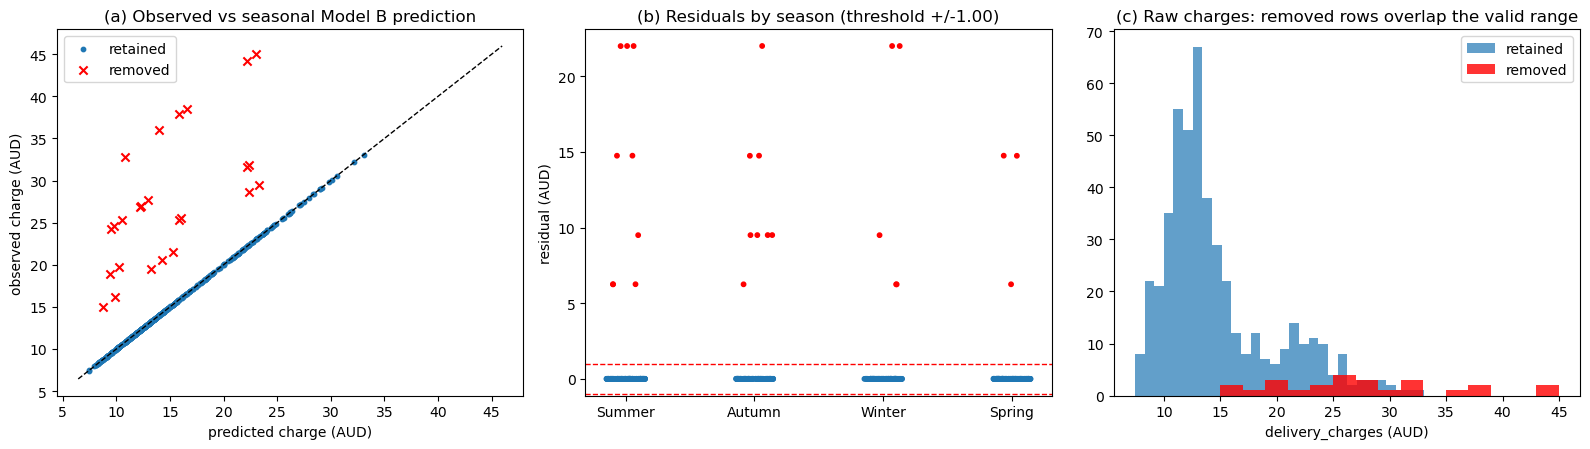

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].scatter(retained["predicted_charge"], retained["delivery_charges"], s=10, label="retained")
axes[0].scatter(flagged["predicted_charge"], flagged["delivery_charges"], s=35, c="red", marker="x", label="removed")
limits = [outlier_work["predicted_charge"].min() - 1, outlier_work["delivery_charges"].max() + 1]
axes[0].plot(limits, limits, "k--", linewidth=1)
axes[0].set_title("(a) Observed vs seasonal Model B prediction")
axes[0].set_xlabel("predicted charge (AUD)"); axes[0].set_ylabel("observed charge (AUD)"); axes[0].legend()

for position, season in enumerate(SEASON_ORDER):
    s = outlier_work[outlier_work["season"] == season]
    jitter = np.random.default_rng(RANDOM_SEED + position).uniform(-0.15, 0.15, len(s))
    axes[1].scatter(position + jitter, s["residual"], s=10, c=np.where(s["is_outlier"], "red", "tab:blue"))
for sign in (1, -1):
    axes[1].axhline(sign * OUTLIER_RESIDUAL_THRESHOLD, color="red", linestyle="--", linewidth=1)
axes[1].set_xticks(range(4), SEASON_ORDER)
axes[1].set_title("(b) Residuals by season (threshold +/-1.00)"); axes[1].set_ylabel("residual (AUD)")

axes[2].hist(retained["delivery_charges"], bins=30, alpha=0.7, label="retained")
axes[2].hist(flagged["delivery_charges"], bins=15, alpha=0.8, color="red", label="removed")
axes[2].set_title("(c) Raw charges: removed rows overlap the valid range")
axes[2].set_xlabel("delivery_charges (AUD)"); axes[2].legend()
plt.tight_layout()
plt.show()

**Unusual but valid orders vs anomalous charges.** Below, the residual rule is compared with a
naive per-season 1.5×IQR screen on *raw* charges. The highest retained charges are also listed.

In [45]:
def iqr_flags(values):
    """Classic 1.5 x IQR fence on raw values (comparison only).

    Parameters
    ----------
    values : pandas.Series
        Raw delivery charges of one season.
    """
    q1, q3 = values.quantile([0.25, 0.75])
    return (values < q1 - 1.5 * (q3 - q1)) | (values > q3 + 1.5 * (q3 - q1))


raw_flag = outlier_work.groupby("season", group_keys=False)["delivery_charges"].apply(iqr_flags)
display(pd.crosstab(raw_flag.rename("raw IQR flag"), outlier_work["is_outlier"].rename("residual rule")))
columns = ["order_id", "season", "distance_to_nearest_warehouse", "is_expedited_delivery",
           "is_happy_customer", "delivery_charges", "predicted_charge", "residual"]
print("Highest retained charges (expensive but consistent with their predictors):")
display(retained.nlargest(8, "delivery_charges")[columns].round(3))
print(f"Removed rows whose raw charge lies inside the retained range "
      f"({retained['delivery_charges'].min():.2f}-{retained['delivery_charges'].max():.2f}): "
      f"{int((flagged['delivery_charges'] <= retained['delivery_charges'].max()).sum())} of {len(flagged)}")
display(flagged.sort_values("residual")[columns + ["total_fits_observed_charge", "implied_charge"]].round(3))

residual rule,False,True
raw IQR flag,,
False,430,8
True,45,17


Highest retained charges (expensive but consistent with their predictors):


,order_id,season,distance_to_nearest_warehouse,is_expedited_delivery,is_happy_customer,delivery_charges,predicted_charge,residual
228,CORD001229,Winter,7.154,True,False,33.08,33.080,-0.000
106,CORD001107,Winter,6.075,True,False,32.16,32.164,-0.004
306,CORD001307,Winter,4.171,True,False,30.55,30.545,0.005
115,CORD001116,Winter,8.327,True,True,30.08,30.077,0.003
460,CORD001461,Winter,8.088,True,True,29.87,29.874,-0.004
382,CORD001383,Winter,7.227,True,True,29.14,29.142,-0.002
375,CORD001376,Winter,7.027,True,True,28.97,28.972,-0.002
473,CORD001474,Winter,2.305,True,False,28.96,28.959,0.001


Removed rows whose raw charge lies inside the retained range (7.43-33.08): 20 of 25


,order_id,season,distance_to_nearest_warehouse,is_expedited_delivery,is_happy_customer,delivery_charges,predicted_charge,residual,total_fits_observed_charge,implied_charge
407,CORD001408,Winter,6.157,False,True,21.48,15.234,6.246,False,15.23
367,CORD001368,Winter,5.025,False,True,20.52,14.272,6.248,False,14.27
99,CORD001100,Summer,7.516,True,True,29.51,23.262,6.248,False,23.26
143,CORD001144,Autumn,2.220,False,True,14.98,8.732,6.248,False,8.73
123,CORD001124,Spring,7.847,False,True,19.48,13.229,6.251,False,13.23
415,CORD001416,Summer,3.366,True,False,28.61,22.358,6.252,False,22.36
119,CORD001120,Summer,2.694,False,True,16.14,9.886,6.254,False,9.89
92,CORD001093,Winter,6.814,False,True,25.29,15.793,9.497,False,15.79
420,CORD001421,Summer,3.188,False,True,19.73,10.232,9.498,False,10.23
252,CORD001253,Autumn,7.691,False,False,25.50,16.000,9.500,False,16.00


**Interpretation.**

* **What was removed.** 25 rows (5%) are removed. Every one has a positive residual between
  about AUD 6.25 and AUD 22.
* **Raw screening fails.** Most removed charges lie inside the valid range. For example,
  CORD001144's AUD 14.98 looks ordinary, but its predictors imply only about AUD 8.73. The raw
  IQR screen misses several anomalies and would delete dozens of valid orders.
* **Valid expensive orders are kept.** The most expensive retained orders are expedited,
  distant and/or unhappy Winter orders. Their charges match the model to within a cent, so they
  are unusual but valid.
* **Corroboration.** In every removed row, the stored `order_total` matches the charge the
  model *expects*, not the observed charge. In every retained row, the total matches the
  observed charge. This is consistent with only the charge having been altered. A trimmed
  within-batch fit and a robust-z rule both select the identical set.
* **Removal, not repair.** As required, outlier rows are removed, not repaired, and retained
  rows are not altered.

In [46]:
outlier_change_records = []


def record_outlier_removal(records, order_id, method, evidence, confidence="high"):
    """Append one removed outlier row to an audit-record list (final Task 2 column order).

    Parameters
    ----------
    records : list of dict
        Mutable list that collects audit records.
    order_id : str
        Stable identifier of the removed order.
    method : str
        Decision rule used.
    evidence : str
        Traceable notebook evidence supporting the removal.
    confidence : str, default "high"
        Confidence level using the definitions in 1.0.8.
    """
    if confidence not in {"high", "medium", "low"}:
        raise ValueError("confidence must be high, medium or low")
    records.append({
        "source_file": OUTLIER_SOURCE_FILENAME,
        "record_key": str(order_id),
        "field_name": "delivery_charges",
        "issue_type": "outlier_row",
        "original_value": outlier_source_text.at[order_id, "delivery_charges"],
        "corrected_value": "ROW_REMOVED",
        "method": method,
        "evidence": evidence,
        "confidence": confidence,
    })


for r in flagged.itertuples():
    record_outlier_removal(
        outlier_change_records, r.order_id,
        f"Seasonal delivery-model residual rule: |residual| > {OUTLIER_RESIDUAL_THRESHOLD:.2f} AUD (Model B)",
        f"Section 1.3; {r.season} predicted {r.predicted_charge:.2f}, observed {r.delivery_charges:.2f}, "
        f"residual {r.residual:+.2f} (robust z {r.robust_z:.0f}); stored total implies {r.implied_charge:.2f}")

outlier_clean = outlier_source.loc[~outlier_work["is_outlier"]].copy(deep=True)
assert len(outlier_clean) + len(outlier_change_records) == EXPECTED_ROWS_PER_BATCH
assert list(outlier_clean.columns) == EXPECTED_COLUMNS and outlier_clean.isna().sum().sum() == 0
outlier_clean.to_csv(OUTLIER_OUTPUT, index=False, encoding="utf-8", columns=EXPECTED_COLUMNS)
print(f"Created {OUTLIER_OUTPUT} with {len(outlier_clean)} retained rows; {len(outlier_change_records)} rows removed.")

Created Group018_outlier_clean.csv with 475 retained rows; 25 rows removed.


## Task 2 - Audit trail and validation

### 2.1 Generate `audit_log.csv`

In 1.1, 1.2 and 1.3, every repair, imputation and outlier removal was added to a list of change
records **at the moment the code made the change**. This means the log shows what the code actually
did, rather than something we put together afterwards. This cell joins the three lists, checks the
log's structure, and writes it to a file.

How the log is filled in:

* there is one row for each changed field and one row for each removed outlier; unchanged cells and
  CSV quoting differences are not logged;
* `original_value` is the exact text from the raw CSV (`<MISSING>` if the cell was empty);
* `corrected_value` is the value we submitted, or `ROW_REMOVED` for a removed outlier, in which case
  `field_name` is `delivery_charges`;
* `evidence` gives the notebook section (and the rule ID for dirty repairs) and the main number
  behind the decision;
* `confidence` uses the high / medium / low levels defined in 1.0.8.

In [47]:
ISSUE_TYPE_BY_SOURCE = {
    DIRTY_INPUT.name: "dirty",
    MISSING_INPUT.name: "missing",
    OUTLIER_INPUT.name: "outlier_row",
}

audit_log = pd.concat(
    [
        pd.DataFrame(dirty_change_records, columns=AUDIT_COLUMNS),
        pd.DataFrame(missing_change_records, columns=AUDIT_COLUMNS),
        pd.DataFrame(outlier_change_records, columns=AUDIT_COLUMNS),
    ],
    ignore_index=True,
)
# Sort by batch, then order ID, then field, so the log is easy to read.
audit_log["_batch_order"] = audit_log["source_file"].map(list(ISSUE_TYPE_BY_SOURCE).index)
audit_log = (
    audit_log.sort_values(["_batch_order", "record_key", "field_name"])
    .drop(columns="_batch_order")
    .reset_index(drop=True)[AUDIT_COLUMNS]
)

# Check the log's structure before writing it.
assert audit_log.notna().all().all() and (audit_log.astype(str).apply(lambda s: s.str.strip()) != "").all().all()
assert not audit_log.duplicated(["source_file", "record_key", "field_name"]).any()
assert set(audit_log["confidence"]) <= {"high", "medium", "low"}
assert (audit_log["source_file"].map(ISSUE_TYPE_BY_SOURCE) == audit_log["issue_type"]).all()

audit_log.to_csv(AUDIT_OUTPUT, index=False, encoding="utf-8")
print(f"Created {AUDIT_OUTPUT} with {len(audit_log)} rows.")

display(
    audit_log.groupby(["source_file", "issue_type", "field_name"]).size()
    .rename("audit_rows").to_frame()
)
display(
    pd.crosstab(audit_log["issue_type"], audit_log["confidence"], margins=True)
)
with pd.option_context("display.max_colwidth", 70):
    display(audit_log.groupby("issue_type", sort=False).head(2))

Created audit_log.csv with 187 rows.


audit_rows
source_file               issue_type  field_name                               
Group018_dirty_data.csv   dirty       customer_lat                            8
                                      date                                    8
                                      delivery_charges                        8
                                      distance_to_nearest_warehouse           8
                                      is_expedited_delivery                   8
                                      is_happy_customer                       8
                                      nearest_warehouse                       9
                                      order_price                             8
                                      order_total                             8
                                      season                                  8
Group018_missing_data.csv missing     delivery_charges                       10
                                      distance_to_nearest_warehouse          10
                                      is_expedited_delivery                  10
                                      is_happy_customer                      10
                                      nearest_warehouse                      11
                                      order_price                            10
                                      order_total                            10
                                      season                                 10
Group018_outlier_data.csv outlier_row delivery_charges                       25

confidence,high,medium,All
issue_type,,,
dirty,77,4,81
missing,81,0,81
outlier_row,25,0,25
All,183,4,187


,source_file,record_key,field_name,issue_type,original_value,corrected_value,method,evidence,confidence
0,Group018_dirty_data.csv,CORD000003,customer_lat,dirty,37.774609,-37.774609,Latitude sign restored (southern hemisphere); longitude is guarant...,Section 1.1 D2; -lat reproduces stored Bakers and 4.2688 km exactly,high
1,Group018_dirty_data.csv,CORD000023,is_expedited_delivery,dirty,False,True,Boolean option with the smaller seasonal delivery-model residual,Section 1.1 D11; residual +10.497 (stored False) vs -0.002 (flipped),high
81,Group018_missing_data.csv,CORD000503,delivery_charges,missing,<MISSING>,23.26,Rearranged published order-total equation,Section 1.2.6; forward total recalculation within AUD 0.01,high
82,Group018_missing_data.csv,CORD000507,is_happy_customer,missing,<MISSING>,False,Frozen local VADER compound score with threshold >= 0.05,Section 1.2.8; resource checksum and NLTK version verified,high
162,Group018_outlier_data.csv,CORD001014,delivery_charges,outlier_row,25.26,ROW_REMOVED,Seasonal delivery-model residual rule: |residual| > 1.00 AUD (Mode...,"Section 1.3; Autumn predicted 10.51, observed 25.26, residual +14....",high
163,Group018_outlier_data.csv,CORD001093,delivery_charges,outlier_row,25.29,ROW_REMOVED,Seasonal delivery-model residual rule: |residual| > 1.00 AUD (Mode...,"Section 1.3; Winter predicted 15.79, observed 25.29, residual +9.5...",high


**Result.** The log has 187 records: 81 dirty repairs (one field in each of 81 rows), 81 missing
values filled in, and 25 outlier rows removed.

* **high (183).** These values come from fixed rules that are also confirmed by a second
  relationship, or from model-based choices (expedited flags, outlier removals) where the chosen
  option is better than the alternative by several AUD of residual.
* **medium (4).** These are four `season` repairs in the dirty file (rule D6). The stated season
  does not match the date, and the date is the field that agrees with everything else. However, for
  these orders the delivery model only shows a small difference (about AUD 0.08 to 0.30) between
  the date's season and the stated season, so the model gives weaker support than for the other
  repairs. The repair still follows the month-to-season rule from the spec, so we keep it and mark
  it as medium instead of hiding the uncertainty.

The confidence table above is created from the records, so it would update automatically if any
decision changed.

### 2.2 Read-back validation of the missing-data output (checks M01-M14)

These checks read `Group018_missing_clean.csv` back from the file on disk. They only check the
finished output and do not change any values used in the cleaning.

In [48]:
# record_validation_result is defined once in 1.0.8; start a new result list for this batch.
validation_results = []

### 2.2.1 Read-back structure, completeness and preservation

This cell reads the submitted missing-data CSV from disk rather than validating only the in-memory
DataFrame. It checks schema, column order, row count, completeness and ID preservation. It also
compares every originally observed source cell with the corresponding output cell so valid values
cannot be silently changed.

In [49]:
missing_output_readback = pd.read_csv(
    MISSING_OUTPUT,
    dtype={"order_id": "string", "customer_id": "string"},
)

schema_passed = list(missing_output_readback.columns) == EXPECTED_COLUMNS
row_and_id_passed = (
    len(missing_output_readback) == EXPECTED_ROWS_PER_BATCH
    and missing_output_readback["order_id"].is_unique
    and set(missing_output_readback["order_id"]) == set(missing_source["order_id"])
)
completeness_passed = int(missing_output_readback.isna().sum().sum()) == 0

preservation_violations = []
source_by_id = missing_source.set_index("order_id")
output_by_id = missing_output_readback.set_index("order_id")

for column_name in EXPECTED_COLUMNS:
    if column_name == "order_id":
        continue
    observed_mask = source_by_id[column_name].notna()
    source_values = source_by_id.loc[observed_mask, column_name].astype(str)
    output_values = output_by_id.loc[observed_mask, column_name].astype(str)
    unequal_ids = source_values.index[source_values != output_values].tolist()
    preservation_violations.extend(
        (order_id, column_name) for order_id in unequal_ids
    )

preservation_passed = len(preservation_violations) == 0

record_validation_result(
    validation_results,
    "M01",
    "Exact schema and column order",
    list(missing_output_readback.columns),
    schema_passed,
    "The output must retain the published 16-column order.",
)
record_validation_result(
    validation_results,
    "M02",
    "Row count and preserved unique IDs",
    f"rows={len(missing_output_readback)}, unique_ids={missing_output_readback['order_id'].nunique()}",
    row_and_id_passed,
    "All 500 original missing-batch orders must remain present exactly once.",
)
record_validation_result(
    validation_results,
    "M03",
    "Required completeness",
    f"missing_cells={int(missing_output_readback.isna().sum().sum())}",
    completeness_passed,
    "Every omission in the missing batch must be recovered.",
)
record_validation_result(
    validation_results,
    "M04",
    "Preservation of originally observed values",
    f"violations={len(preservation_violations)}",
    preservation_passed,
    "Only source cells that were empty may differ in the cleaned output.",
)

### 2.2.2 Business-rule validation

This cell independently recalculates cart prices, seasons, warehouse distances, happiness and
order totals for every read-back row. It also applies the fitted seasonal delivery models to check
that the completed records follow the expected retained-row residual relationship.

In [50]:
cart_errors = []
price_errors = []
season_errors = []
warehouse_errors = []
distance_errors = []
happiness_errors = []
total_errors = []

for output_row in missing_output_readback.itertuples(index=False):
    try:
        parsed_cart = parse_shopping_cart(output_row.shopping_cart)
    except (TypeError, ValueError, json.JSONDecodeError) as error:
        cart_errors.append((output_row.order_id, str(error)))
        continue

    expected_price = calculate_order_price(parsed_cart, final_unit_prices)
    if abs(expected_price - output_row.order_price) > MONEY_TOLERANCE:
        price_errors.append(output_row.order_id)

    expected_season = get_australian_season(output_row.date)
    if expected_season != output_row.season:
        season_errors.append(output_row.order_id)

    expected_warehouse, expected_distance = find_nearest_warehouse(
        output_row.customer_lat,
        output_row.customer_long,
        warehouses_source,
    )
    if expected_warehouse != output_row.nearest_warehouse:
        warehouse_errors.append(output_row.order_id)
    if (
        abs(expected_distance - output_row.distance_to_nearest_warehouse)
        > DISTANCE_TOLERANCE
    ):
        distance_errors.append(output_row.order_id)

    expected_happiness = classify_customer_happiness(
        output_row.latest_customer_review,
        sentiment_analyser,
    )
    if expected_happiness != output_row.is_happy_customer:
        happiness_errors.append(output_row.order_id)

    expected_total = calculate_order_total(
        output_row.order_price,
        output_row.coupon_discount,
        output_row.delivery_charges,
    )
    if abs(expected_total - output_row.order_total) > MONEY_TOLERANCE:
        total_errors.append(output_row.order_id)

relationship_checks = [
    ("M05", "Valid shopping-cart structure", cart_errors),
    ("M06", "Cart-derived current order prices", price_errors),
    ("M07", "Calendar season relationship", season_errors),
    ("M08", "Nearest-warehouse relationship", warehouse_errors),
    ("M09", "Haversine-distance relationship", distance_errors),
    ("M10", "VADER happiness relationship", happiness_errors),
    ("M11", "Discount and order-total arithmetic", total_errors),
]

for check_id, check_name, errors in relationship_checks:
    record_validation_result(
        validation_results,
        check_id,
        check_name,
        f"violations={len(errors)}",
        len(errors) == 0,
        "The read-back values agree with the published rule and shared functions.",
    )

completed_model_residuals = []
for season_name in SEASON_ORDER:
    season_rows = missing_output_readback.loc[
        missing_output_readback["season"] == season_name
    ]
    predictions = predict_delivery_charges(
        season_rows,
        seasonal_delivery_models[season_name],
    )
    observed_charges = season_rows["delivery_charges"].to_numpy(dtype=float)
    completed_model_residuals.extend(
        np.abs(observed_charges - predictions).tolist()
    )

maximum_completed_residual = max(completed_model_residuals)
record_validation_result(
    validation_results,
    "M12",
    "Seasonal delivery-model residual behaviour",
    f"maximum_absolute_residual={maximum_completed_residual:.6f}",
    maximum_completed_residual <= 0.08,
    "Completed missing-batch rows remain within the delivery-charge tolerance.",
)

### 2.2.3 Difference and audit reconciliation

This cell derives the actual source-to-output differences and compares their order/field keys with
the 81 captured audit records. The check prevents missing audit entries, duplicate entries and audit
claims that do not correspond to a real output change.

In [51]:
actual_difference_keys = set()

for source_row in missing_source.itertuples(index=False):
    order_id = source_row.order_id
    for column_name in EXPECTED_COLUMNS:
        if column_name == "order_id":
            continue
        source_value = source_by_id.at[order_id, column_name]
        output_value = output_by_id.at[order_id, column_name]
        if pd.isna(source_value) and not pd.isna(output_value):
            actual_difference_keys.add((order_id, column_name))

audit_difference_keys = set(
    zip(
        missing_audit_records["record_key"],
        missing_audit_records["field_name"],
    )
)

audit_reconciliation_passed = (
    len(actual_difference_keys) == 81
    and len(audit_difference_keys) == 81
    and actual_difference_keys == audit_difference_keys
)

record_validation_result(
    validation_results,
    "M13",
    "Input/output differences agree with missing audit records",
    (
        f"actual_differences={len(actual_difference_keys)}, "
        f"audit_keys={len(audit_difference_keys)}"
    ),
    audit_reconciliation_passed,
    "Each recovered source omission has one matching Task 2 audit record.",
)

ending_source_hashes = {
    source_name: sha256_file(source_path)
    for source_name, source_path in source_paths.items()
}
source_hashes_passed = ending_source_hashes == initial_source_hashes
record_validation_result(
    validation_results,
    "M14",
    "Raw source files remain unchanged",
    f"unchanged={source_hashes_passed}",
    source_hashes_passed,
    "The workflow reads supplied inputs without overwriting them.",
)

### 2.2.4 Validation summary

This cell presents all missing-output checks in one concise table and stops execution if any check
fails. A passing table demonstrates structural correctness, business-rule consistency, preservation
of valid information and full agreement with the missing-data audit records.

In [52]:
missing_validation_results = pd.DataFrame(validation_results)
display(missing_validation_results)

failed_validation_checks = missing_validation_results.loc[
    missing_validation_results["status"] != "PASS"
]
assert failed_validation_checks.empty, failed_validation_checks.to_dict("records")

final_missing_summary = pd.Series(
    {
        "input_rows": len(missing_source),
        "output_rows": len(missing_output_readback),
        "source_missing_cells": int(original_missing_mask.sum().sum()),
        "output_missing_cells": int(missing_output_readback.isna().sum().sum()),
        "audit_records_prepared": len(missing_audit_records),
        "validation_checks_passed": int(
            (missing_validation_results["status"] == "PASS").sum()
        ),
        "validation_checks_failed": len(failed_validation_checks),
        "final_audit_log_written": AUDIT_OUTPUT.exists(),
    },
    name="missing_task_result",
)
display(final_missing_summary)
print("Missing-value recovery and concurrent Task 2 validation: PASS")

,check_id,check_name,observed_result,status,interpretation
0,M01,Exact schema and column order,"['order_id', 'customer_id', 'date', 'nearest_w...",PASS,The output must retain the published 16-column...
1,M02,Row count and preserved unique IDs,"rows=500, unique_ids=500",PASS,All 500 original missing-batch orders must rem...
2,M03,Required completeness,missing_cells=0,PASS,Every omission in the missing batch must be re...
3,M04,Preservation of originally observed values,violations=0,PASS,Only source cells that were empty may differ i...
4,M05,Valid shopping-cart structure,violations=0,PASS,The read-back values agree with the published ...
5,M06,Cart-derived current order prices,violations=0,PASS,The read-back values agree with the published ...
6,M07,Calendar season relationship,violations=0,PASS,The read-back values agree with the published ...
7,M08,Nearest-warehouse relationship,violations=0,PASS,The read-back values agree with the published ...
8,M09,Haversine-distance relationship,violations=0,PASS,The read-back values agree with the published ...
9,M10,VADER happiness relationship,violations=0,PASS,The read-back values agree with the published ...


input_rows                   500
output_rows                  500
source_missing_cells          81
output_missing_cells           0
audit_records_prepared        81
validation_checks_passed      14
validation_checks_failed       0
final_audit_log_written     True
Name: missing_task_result, dtype: object

Missing-value recovery and concurrent Task 2 validation: PASS


### 2.3 Read-back validation of the dirty and outlier outputs (checks D01-D13, O01-O13, DO14)

Both cleaned files are read back from disk, and each check records what it found, whether it passed
or failed, and what this means. The check IDs start with `D` for the dirty file and `O` for the
outlier file, next to `M01`-`M14` above. These checks only read the finished outputs and do not
change anything used in the cleaning.

In [53]:
dirty_outlier_validation_results = []
dirty_readback = pd.read_csv(DIRTY_OUTPUT, dtype={"order_id": str, "customer_id": str})
outlier_readback = pd.read_csv(OUTLIER_OUTPUT, dtype={"order_id": str, "customer_id": str})
dirty_audit_records = pd.DataFrame(dirty_change_records, columns=AUDIT_COLUMNS)
outlier_audit_records = pd.DataFrame(outlier_change_records, columns=AUDIT_COLUMNS)


def business_rule_checks(results, prefix, readback):
    """Recompute every published relationship on a read-back output and record each result.

    Parameters
    ----------
    results : list of dict
        Validation results list passed to record_validation_result.
    prefix : str
        Check-ID prefix ("D" or "O").
    readback : pandas.DataFrame
        Output CSV re-read from disk.
    """
    expected = derive_expected_values(readback)
    flags = flag_rule_violations(readback, expected)
    cart_errors = 0
    for cart_text in readback["shopping_cart"]:
        try:
            parse_shopping_cart(cart_text)
        except (TypeError, ValueError, json.JSONDecodeError):
            cart_errors += 1
    checks = [
        ("05", "Valid shopping-cart structure", cart_errors),
        ("06", "Cart-derived current order prices", int(flags["price_vs_cart"].sum())),
        ("07", "ISO dates and calendar season", int((flags["date_not_iso"] | flags["season_vs_date"]).sum())),
        ("08", "Melbourne coordinates and nearest warehouse",
         int((flags["coords_outside_melbourne"] | flags["warehouse_label_invalid"] | flags["warehouse_vs_coords"]).sum())),
        ("09", "Haversine-distance relationship", int(flags["distance_vs_coords"].sum())),
        ("10", "VADER happiness relationship", int(flags["happy_vs_review"].sum())),
        ("11", "Discount and order-total arithmetic", int(flags["total_vs_arithmetic"].sum())),
    ]
    for number, name, violations in checks:
        record_validation_result(results, f"{prefix}{number}", name, f"violations={violations}", violations == 0,
                                 "The read-back values agree with the published rule and shared functions.")
    residual = (readback["delivery_charges"] - predict_batch(model_b, readback)).abs().max()
    record_validation_result(results, f"{prefix}12", "Seasonal delivery-model residual behaviour",
                             f"maximum_absolute_residual={residual:.6f}", residual <= 0.08,
                             "Every retained charge stays within the delivery-charge tolerance of its seasonal model.")


def changed_cells(source, output):
    """Set of (order_id, field) cells whose meaning differs between source and output.

    Parameters
    ----------
    source, output : pandas.DataFrame
        Source batch and read-back output with the same columns.
    """
    source_by_id, output_by_id = source.set_index("order_id"), output.set_index("order_id")
    differences = set()
    for order_id in output_by_id.index:
        for column in EXPECTED_COLUMNS[1:]:
            a, b = source_by_id.at[order_id, column], output_by_id.at[order_id, column]
            if isinstance(a, (float, int, np.floating, np.integer)) and not isinstance(a, (bool, np.bool_)):
                same = abs(float(a) - float(b)) <= 1e-9
            else:
                same = str(a) == str(b)
            if not same:
                differences.add((str(order_id), column))
    return differences


# ---- Dirty output
record_validation_result(dirty_outlier_validation_results, "D01", "Exact schema and column order",
                         list(dirty_readback.columns), list(dirty_readback.columns) == EXPECTED_COLUMNS,
                         "The output must retain the published 16-column order.")
record_validation_result(dirty_outlier_validation_results, "D02", "Row count and preserved unique IDs",
                         f"rows={len(dirty_readback)}, unique_ids={dirty_readback['order_id'].nunique()}",
                         len(dirty_readback) == EXPECTED_ROWS_PER_BATCH and dirty_readback["order_id"].is_unique
                         and set(dirty_readback["order_id"]) == set(dirty_source["order_id"]),
                         "All 500 original dirty-batch orders must remain present exactly once.")
record_validation_result(dirty_outlier_validation_results, "D03", "Required completeness",
                         f"missing_cells={int(dirty_readback.isna().sum().sum())}",
                         dirty_readback.isna().sum().sum() == 0, "The repaired output has no empty cells.")
dirty_differences = changed_cells(dirty_source, dirty_readback)
dirty_audit_keys = set(zip(dirty_audit_records["record_key"], dirty_audit_records["field_name"]))
record_validation_result(dirty_outlier_validation_results, "D04", "Preservation of unaudited values",
                         f"unaudited_changes={len(dirty_differences - dirty_audit_keys)}",
                         not (dirty_differences - dirty_audit_keys),
                         "Only cells named in the audit records differ from the source.")
business_rule_checks(dirty_outlier_validation_results, "D", dirty_readback)
readback_by_id = dirty_readback.set_index("order_id")
value_mismatches = 0
for record in dirty_audit_records.itertuples():
    output_value = readback_by_id.at[record.record_key, record.field_name]
    if format_audit_value(record.field_name, output_value) != record.corrected_value \
            or dirty_source_text.at[record.record_key, record.field_name] != record.original_value:
        value_mismatches += 1
record_validation_result(dirty_outlier_validation_results, "D13", "Input/output differences agree with dirty audit records",
                         f"actual_differences={len(dirty_differences)}, audit_keys={len(dirty_audit_keys)}, "
                         f"value_mismatches={value_mismatches}",
                         dirty_differences == dirty_audit_keys and value_mismatches == 0
                         and not dirty_audit_records.duplicated(["record_key", "field_name"]).any(),
                         "Each repair has one record with the true original and submitted value; no extra records.")

# ---- Outlier output
removed_ids = set(outlier_audit_records["record_key"])
retained_ids = set(outlier_readback["order_id"])
record_validation_result(dirty_outlier_validation_results, "O01", "Exact schema and column order",
                         list(outlier_readback.columns), list(outlier_readback.columns) == EXPECTED_COLUMNS,
                         "The output must retain the published 16-column order.")
record_validation_result(dirty_outlier_validation_results, "O02", "Retained and removed IDs reconcile with input",
                         f"retained={len(retained_ids)}, removed={len(removed_ids)}, input={outlier_source['order_id'].nunique()}",
                         outlier_readback["order_id"].is_unique and retained_ids.isdisjoint(removed_ids)
                         and retained_ids | removed_ids == set(outlier_source["order_id"]),
                         "Every input ID is either retained or recorded as ROW_REMOVED, never both.")
record_validation_result(dirty_outlier_validation_results, "O03", "Required completeness",
                         f"missing_cells={int(outlier_readback.isna().sum().sum())}",
                         outlier_readback.isna().sum().sum() == 0, "Retained rows have no empty cells.")
outlier_differences = changed_cells(outlier_source, outlier_readback)
record_validation_result(dirty_outlier_validation_results, "O04", "Retained rows unchanged",
                         f"changed_cells={len(outlier_differences)}", not outlier_differences,
                         "Outlier treatment removes rows; it never edits retained values.")
business_rule_checks(dirty_outlier_validation_results, "O", outlier_readback)
removed_residual = outlier_work.set_index("order_id").loc[sorted(removed_ids), "residual"].abs()
record_validation_result(dirty_outlier_validation_results, "O13", "Removal records agree with removed rows",
                         f"records={len(outlier_audit_records)}, min_removed_|residual|={removed_residual.min():.4f}",
                         set(outlier_audit_records["corrected_value"]) == {"ROW_REMOVED"}
                         and set(outlier_audit_records["issue_type"]) == {"outlier_row"}
                         and removed_residual.min() > OUTLIER_RESIDUAL_THRESHOLD
                         and not outlier_audit_records["record_key"].duplicated().any(),
                         "One ROW_REMOVED record per removed order, each above the decision threshold.")

ending_source_hashes = {name: sha256_file(path) for name, path in source_paths.items()}
record_validation_result(dirty_outlier_validation_results, "DO14", "Raw source files remain unchanged",
                         f"unchanged={ending_source_hashes == initial_source_hashes}",
                         ending_source_hashes == initial_source_hashes,
                         "The workflow reads supplied inputs without overwriting them.")

In [54]:
dirty_outlier_validation = pd.DataFrame(dirty_outlier_validation_results)
display(dirty_outlier_validation)
failed_checks = dirty_outlier_validation[dirty_outlier_validation["status"] != "PASS"]
assert failed_checks.empty, failed_checks.to_dict("records")

display(pd.concat([dirty_audit_records, outlier_audit_records])
        .groupby(["source_file", "issue_type", "field_name"]).size().rename("audit_rows").to_frame())
display(pd.Series({
    "dirty input / output rows": f"{len(dirty_source)} / {len(dirty_readback)}",
    "dirty audit records prepared": len(dirty_audit_records),
    "outlier input / retained / removed": f"{len(outlier_source)} / {len(outlier_readback)} / {len(outlier_audit_records)}",
    "outlier audit records prepared": len(outlier_audit_records),
    "validation_checks_passed": int((dirty_outlier_validation["status"] == "PASS").sum()),
    "validation_checks_failed": len(failed_checks),
    "final_audit_log_written": AUDIT_OUTPUT.exists(),
}, name="dirty_outlier_task_result").to_frame())
print("Dirty repair, outlier removal and concurrent Task 2 validation: PASS")

,check_id,check_name,observed_result,status,interpretation
0,D01,Exact schema and column order,"['order_id', 'customer_id', 'date', 'nearest_w...",PASS,The output must retain the published 16-column...
1,D02,Row count and preserved unique IDs,"rows=500, unique_ids=500",PASS,All 500 original dirty-batch orders must remai...
2,D03,Required completeness,missing_cells=0,PASS,The repaired output has no empty cells.
3,D04,Preservation of unaudited values,unaudited_changes=0,PASS,Only cells named in the audit records differ f...
4,D05,Valid shopping-cart structure,violations=0,PASS,The read-back values agree with the published ...
5,D06,Cart-derived current order prices,violations=0,PASS,The read-back values agree with the published ...
6,D07,ISO dates and calendar season,violations=0,PASS,The read-back values agree with the published ...
7,D08,Melbourne coordinates and nearest warehouse,violations=0,PASS,The read-back values agree with the published ...
8,D09,Haversine-distance relationship,violations=0,PASS,The read-back values agree with the published ...
9,D10,VADER happiness relationship,violations=0,PASS,The read-back values agree with the published ...


audit_rows
source_file               issue_type  field_name                               
Group018_dirty_data.csv   dirty       customer_lat                            8
                                      date                                    8
                                      delivery_charges                        8
                                      distance_to_nearest_warehouse           8
                                      is_expedited_delivery                   8
                                      is_happy_customer                       8
                                      nearest_warehouse                       9
                                      order_price                             8
                                      order_total                             8
                                      season                                  8
Group018_outlier_data.csv outlier_row delivery_charges                       25

,dirty_outlier_task_result
dirty input / output rows,500 / 500
dirty audit records prepared,81
outlier input / retained / removed,500 / 475 / 25
outlier audit records prepared,25
validation_checks_passed,27
validation_checks_failed,0
final_audit_log_written,True


Dirty repair, outlier removal and concurrent Task 2 validation: PASS


**What the checks establish, and their limits.**

* **What passes.** Both outputs are re-read from disk and pass the schema, ID, completeness and
  preservation checks. Every published relationship holds, and every retained charge fits its
  seasonal model.
* **Audit reconciliation (D13 and O13).** Every difference between input and output has exactly
  one audit record with the true original and submitted values, and every removed ID has one
  `ROW_REMOVED` record. Section 2.4 repeats this check against the written `audit_log.csv` file itself.
* **What they cannot prove.** Passing checks do not prove that each value equals the reference
  answer. The 8 expedited repairs rest on the seasonal model rather than a deterministic rule.
  The D6 and D9/D10 attributions depend on the model witness and on the one-error guarantee;
  the rule checks would pass either way. The wide residual separation shown in 1.1 is our
  evidence for those choices.

### 2.4 Read-back validation of `audit_log.csv` (checks A01-A08)

The checks in 2.2 and 2.3 compare each output with the change records in memory. The checks here
start from the **files on disk** instead: the raw input CSVs, the three submitted CSVs and the
submitted `audit_log.csv`, all read as plain text. A cell only counts as changed when its *meaning*
is different, using the equivalence rules in Section 5 of the spec:

* numbers are compared as floats (so `8` and `8.00` are the same);
* booleans treat `True`/`False`/`1`/`0` as equal, ignoring upper or lower case;
* shopping carts are compared after parsing the JSON;
* all other fields (IDs, dates, labels, review text) must match exactly as text.

This means the log can be checked independently: every change in the log must appear in the files,
and every change in the files must appear in the log.

In [55]:
audit_validation_results = []

audit_readback = pd.read_csv(AUDIT_OUTPUT, dtype=str, keep_default_na=False)

NUMERIC_FIELDS = {
    "order_price", "delivery_charges", "customer_lat", "customer_long",
    "coupon_discount", "order_total", "distance_to_nearest_warehouse",
}
BOOLEAN_FIELDS = {"is_expedited_delivery", "is_happy_customer"}


def canonical_cell(field_name, text):
    """Return a comparable representation of one CSV cell under the spec's equivalence rules.

    Parameters
    ----------
    field_name : str
        Column the cell belongs to.
    text : str
        Raw CSV text of the cell ("" for an empty field).
    """
    if text == "" or text == "<MISSING>":
        return None
    if field_name in NUMERIC_FIELDS:
        return round(float(text), 9)
    if field_name in BOOLEAN_FIELDS:
        lowered = text.strip().lower()
        if lowered in {"true", "1", "1.0"}:
            return True
        if lowered in {"false", "0", "0.0"}:
            return False
        return ("UNPARSEABLE_BOOLEAN", text)
    if field_name == "shopping_cart":
        return json.dumps(json.loads(text), sort_keys=True)
    return text


def read_as_text(path):
    """Read a CSV with every cell as raw text, indexed by order_id.

    Parameters
    ----------
    path : pathlib.Path
        CSV to read.
    """
    return pd.read_csv(path, dtype=str, keep_default_na=False).set_index("order_id", drop=False)


def file_differences(raw, output):
    """Return {(order_id, field): (raw_text, output_text)} for cells whose meaning changed.

    Parameters
    ----------
    raw, output : pandas.DataFrame
        Text-typed raw input and cleaned output, indexed by order_id. Only IDs present in
        the output are compared.
    """
    differences = {}
    for order_id in output.index:
        for field_name in EXPECTED_COLUMNS[1:]:
            raw_text = raw.at[order_id, field_name]
            output_text = output.at[order_id, field_name]
            if canonical_cell(field_name, raw_text) != canonical_cell(field_name, output_text):
                differences[(order_id, field_name)] = (raw_text, output_text)
    return differences


batch_files = {
    "dirty": (DIRTY_INPUT, DIRTY_OUTPUT),
    "missing": (MISSING_INPUT, MISSING_OUTPUT),
    "outlier": (OUTLIER_INPUT, OUTLIER_OUTPUT),
}
raw_text_by_batch = {name: read_as_text(paths[0]) for name, paths in batch_files.items()}
output_text_by_batch = {name: read_as_text(paths[1]) for name, paths in batch_files.items()}
audit_by_batch = {
    name: audit_readback[audit_readback["source_file"] == paths[0].name]
    for name, paths in batch_files.items()
}

# A01 schema of the audit log
record_validation_result(
    audit_validation_results, "A01", "Audit log exact schema and column order",
    list(audit_readback.columns), list(audit_readback.columns) == AUDIT_COLUMNS,
    "The submitted log has the nine required columns in the required order.",
)

# A02 completeness and allowed values
empty_cells = int((audit_readback.apply(lambda s: s.str.strip()) == "").to_numpy().sum())
bad_source = ~audit_readback["source_file"].isin(ISSUE_TYPE_BY_SOURCE)
bad_issue = audit_readback["source_file"].map(ISSUE_TYPE_BY_SOURCE) != audit_readback["issue_type"]
bad_confidence = ~audit_readback["confidence"].isin(["high", "medium", "low"])
bad_field = ~audit_readback["field_name"].isin(EXPECTED_COLUMNS[1:])
is_outlier_record = audit_readback["issue_type"] == "outlier_row"
bad_outlier_convention = is_outlier_record & (
    (audit_readback["field_name"] != "delivery_charges")
    | (audit_readback["corrected_value"] != "ROW_REMOVED")
)
bad_removed_marker = ~is_outlier_record & (audit_readback["corrected_value"] == "ROW_REMOVED")
bad_missing_marker = (audit_readback["issue_type"] == "missing") != (
    audit_readback["original_value"] == "<MISSING>"
)
a02_problems = {
    "empty_cells": empty_cells,
    "unknown_source_file": int(bad_source.sum()),
    "issue_type_mismatch": int(bad_issue.sum()),
    "invalid_confidence": int(bad_confidence.sum()),
    "invalid_field_name": int(bad_field.sum()),
    "outlier_convention": int(bad_outlier_convention.sum()),
    "misplaced_ROW_REMOVED": int(bad_removed_marker.sum()),
    "misplaced_<MISSING>": int(bad_missing_marker.sum()),
}
record_validation_result(
    audit_validation_results, "A02", "Audit log completeness and value conventions",
    a02_problems, sum(a02_problems.values()) == 0,
    "Every cell is filled; source files, issue types, fields, markers and confidence levels "
    "follow the published conventions.",
)

# A03 keys are unique and exist in the raw input
duplicate_keys = int(audit_readback.duplicated(["source_file", "record_key", "field_name"]).sum())
untraceable_keys = sum(
    int((~audit_by_batch[name]["record_key"].isin(raw_text_by_batch[name].index)).sum())
    for name in batch_files
)
record_validation_result(
    audit_validation_results, "A03", "Audit keys unique and present in the raw input",
    f"duplicate_keys={duplicate_keys}, keys_not_in_source={untraceable_keys}",
    duplicate_keys == 0 and untraceable_keys == 0,
    "Each changed field is logged once, and every record_key is an order_id of its source file.",
)

# A04-A06 compare the files with the log, batch by batch
reconciliation_rows = []
for name in ["dirty", "missing"]:
    raw, output, log = raw_text_by_batch[name], output_text_by_batch[name], audit_by_batch[name]
    differences = file_differences(raw, output)
    logged_keys = set(zip(log["record_key"], log["field_name"]))
    value_mismatches = 0
    for record in log.itertuples(index=False):
        key = (record.record_key, record.field_name)
        if key not in differences:
            continue
        raw_text, output_text = differences[key]
        original_ok = record.original_value == (raw_text if raw_text != "" else "<MISSING>")
        corrected_ok = canonical_cell(record.field_name, record.corrected_value) == canonical_cell(
            record.field_name, output_text
        )
        value_mismatches += int(not (original_ok and corrected_ok))
    reconciliation_rows.append({
        "batch": name,
        "file_differences": len(differences),
        "audit_records": len(log),
        "changed_but_not_logged": len(set(differences) - logged_keys),
        "logged_but_not_changed": len(logged_keys - set(differences)),
        "value_mismatches": value_mismatches,
        "ids_retained": f"{output.index.nunique()}/{raw.index.nunique()}",
    })

for check_id, row in zip(["A04", "A05"], reconciliation_rows):
    passed = (
        row["changed_but_not_logged"] == 0
        and row["logged_but_not_changed"] == 0
        and row["value_mismatches"] == 0
        and set(output_text_by_batch[row["batch"]].index) == set(raw_text_by_batch[row["batch"]].index)
    )
    record_validation_result(
        audit_validation_results, check_id,
        f"{row['batch'].capitalize()} files and audit log agree cell-for-cell",
        {k: v for k, v in row.items() if k != "batch"}, passed,
        "The set of changed cells in the files equals the set of logged fields, and each record's "
        "original/corrected values match the raw and submitted files.",
    )

raw, output, log = raw_text_by_batch["outlier"], output_text_by_batch["outlier"], audit_by_batch["outlier"]
removed_in_files = set(raw.index) - set(output.index)
removed_in_log = set(log["record_key"])
retained_changes = file_differences(raw, output)
removed_value_mismatches = int(sum(
    record.original_value != raw.at[record.record_key, "delivery_charges"]
    for record in log.itertuples(index=False)
))
outlier_reconciliation = {
    "input": raw.index.nunique(),
    "retained": output.index.nunique(),
    "removed_in_files": len(removed_in_files),
    "removed_in_log": len(removed_in_log),
    "unexpected_ids": len(set(output.index) - set(raw.index)),
    "retained_cells_changed": len(retained_changes),
    "original_value_mismatches": removed_value_mismatches,
}
reconciliation_rows.append({"batch": "outlier", **outlier_reconciliation})
record_validation_result(
    audit_validation_results, "A06", "Outlier files and audit log agree on removed and retained IDs",
    outlier_reconciliation,
    removed_in_files == removed_in_log
    and not (set(output.index) - set(raw.index))
    and not retained_changes
    and removed_value_mismatches == 0,
    "Every removed ID has one ROW_REMOVED record quoting its raw charge; retained rows are unchanged.",
)

# A07 order IDs unique within and across outputs
all_output_ids = pd.concat([frame["order_id"] for frame in output_text_by_batch.values()])
record_validation_result(
    audit_validation_results, "A07", "Order IDs unique within and across the three outputs",
    f"ids={len(all_output_ids)}, distinct={all_output_ids.nunique()}",
    all_output_ids.is_unique,
    "Retained orders are distinct within and across batches, as the specification guarantees for the inputs.",
)

# A08 the log on disk equals the records the code produced
round_trip_equal = audit_readback.equals(audit_log.astype(str))
record_validation_result(
    audit_validation_results, "A08", "Written audit log equals the in-memory change records",
    f"rows_on_disk={len(audit_readback)}, rows_in_memory={len(audit_log)}, identical={round_trip_equal}",
    round_trip_equal,
    "No record was lost, altered or added when writing; the log is exactly what the code recorded.",
)

display(pd.DataFrame(reconciliation_rows).set_index("batch"))
audit_validation = pd.DataFrame(audit_validation_results)
with pd.option_context("display.max_colwidth", 120):
    display(audit_validation)

,file_differences,audit_records,changed_but_not_logged,logged_but_not_changed,value_mismatches,ids_retained,input,retained,removed_in_files,removed_in_log,unexpected_ids,retained_cells_changed,original_value_mismatches
batch,,,,,,,,,,,,,
dirty,81.0,81.0,0.0,0.0,0.0,500/500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
missing,81.0,81.0,0.0,0.0,0.0,500/500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
outlier,NaN,NaN,NaN,NaN,NaN,NaN,500.0,475.0,25.0,25.0,0.0,0.0,0.0


,check_id,check_name,observed_result,status,interpretation
0,A01,Audit log exact schema and column order,"['source_file', 'record_key', 'field_name', 'issue_type', 'original_value', 'corrected_value', 'method', 'evidence',...",PASS,The submitted log has the nine required columns in the required order.
1,A02,Audit log completeness and value conventions,"{'empty_cells': 0, 'unknown_source_file': 0, 'issue_type_mismatch': 0, 'invalid_confidence': 0, 'invalid_field_name'...",PASS,"Every cell is filled; source files, issue types, fields, markers and confidence levels follow the published conventi..."
2,A03,Audit keys unique and present in the raw input,"duplicate_keys=0, keys_not_in_source=0",PASS,"Each changed field is logged once, and every record_key is an order_id of its source file."
3,A04,Dirty files and audit log agree cell-for-cell,"{'file_differences': 81, 'audit_records': 81, 'changed_but_not_logged': 0, 'logged_but_not_changed': 0, 'value_misma...",PASS,"The set of changed cells in the files equals the set of logged fields, and each record's original/corrected values m..."
4,A05,Missing files and audit log agree cell-for-cell,"{'file_differences': 81, 'audit_records': 81, 'changed_but_not_logged': 0, 'logged_but_not_changed': 0, 'value_misma...",PASS,"The set of changed cells in the files equals the set of logged fields, and each record's original/corrected values m..."
5,A06,Outlier files and audit log agree on removed and retained IDs,"{'input': 500, 'retained': 475, 'removed_in_files': 25, 'removed_in_log': 25, 'unexpected_ids': 0, 'retained_cells_c...",PASS,Every removed ID has one ROW_REMOVED record quoting its raw charge; retained rows are unchanged.
6,A07,Order IDs unique within and across the three outputs,"ids=1475, distinct=1475",PASS,"Retained orders are distinct within and across batches, as the specification guarantees for the inputs."
7,A08,Written audit log equals the in-memory change records,"rows_on_disk=187, rows_in_memory=187, identical=True",PASS,"No record was lost, altered or added when writing; the log is exactly what the code recorded."


### 2.5 Combined validation summary

This table brings all the Task 2 checks together. If any check fails, the cell lists it with its
observed result instead of stopping the notebook, so the problem is reported and not hidden.

In [56]:
all_validation = pd.concat(
    {
        "missing output": missing_validation_results,
        "dirty / outlier outputs": dirty_outlier_validation,
        "audit log": audit_validation,
    },
    names=["check_group", None],
).reset_index(level=0)

display(
    all_validation.groupby("check_group", sort=False)["status"].value_counts()
    .unstack(fill_value=0)
)
failing = all_validation[all_validation["status"] != "PASS"]
if failing.empty:
    print(f"All {len(all_validation)} Task 2 checks PASS.")
else:
    print(f"{len(failing)} of {len(all_validation)} checks FAIL:")
    display(failing)

display(pd.Series({
    "dirty rows in / out": f"{len(dirty_source)} / {len(dirty_readback)}",
    "missing rows in / out": f"{len(missing_source)} / {len(missing_output_readback)}",
    "outlier rows in / retained / removed":
        f"{len(outlier_source)} / {len(outlier_readback)} / {len(outlier_change_records)}",
    "audit_log.csv rows": len(audit_readback),
}, name="Task 1-2 outputs").to_frame())

status,PASS
check_group,
missing output,14
dirty / outlier outputs,27
audit log,8


All 49 Task 2 checks PASS.


,Task 1-2 outputs
dirty rows in / out,500 / 500
missing rows in / out,500 / 500
outlier rows in / retained / removed,500 / 475 / 25
audit_log.csv rows,187


**What Task 2 shows, and its limits**

* **Traceability.** Looking at the files on disk, every difference between a raw input and its
  cleaned output has exactly one audit record, and every audit record matches a real difference
  (A04-A06). The removed and retained outlier IDs add up to the input IDs (O02, A06).
* **Following the rules.** When read back, all three outputs follow every published relationship
  (M05-M12, D05-D12, O05-O12), and the retained delivery charges fit their seasonal models.
* **Keeping valid values.** Values that were already correct are unchanged (M04, D04, O04,
  A04-A06), and the raw input files are exactly the same after the run (M14, DO14).
* **Limits.** Passing these checks shows the outputs are consistent with the rules, but it does not
  prove every value equals the marker's reference answer. Decisions that depend on the seasonal
  model instead of a fixed rule (the expedited-flag repairs and imputations, and the outlier
  removals) are supported by the residual differences shown in 1.1, 1.2.9 and 1.3, not by these
  checks alone.

## Task 3 - Customer profiling and transformation

